# Tema : Modelo Prophet
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

# Ejercicio 1. Demanda diaria de electricidad en Victoria, Australia

- Una aplicación común de estos modelos es el pronóstico de la demanda de electricidad. Tenemos la demanda de electricidad cada media hora (MWh) en Victoria, Australia, durante el periodo 2012-2014, junto con la temperatura (en grados Celsius) en Melbourne, la ciudad más grande de Victoria.
- Para este ejercicio agregamos los datos a frecuencia diaria. La demanda diaria es la suma de las demandas de cada media hora, expresada en GWh, y la temperatura diaria es la temperatura máxima del día.
- El objetivo es pronosticar la demanda de los últimos 90 días de 2014 y comparar varios modelos Prophet con un modelo de referencia y con un modelo de regresión dinámica. Los notebooks de Python y de LSTM usan los mismos datos y el mismo periodo de prueba, de modo que los resultados se pueden comparar.
- Seguimos el enfoque del libro [Forecasting: Principles and Practice](https://otexts.com/fpp3/). El paquete `fable.prophet` permite estimar Prophet con la misma sintaxis de `model()`, `forecast()` y `accuracy()` que usamos con los modelos ARIMA y ETS.

In [1]:
# Librerias necesarias
suppressPackageStartupMessages({
  library(tidyverse)     # Manipulación de datos y gráficos
  library(tsibble)       # Estructura de datos para series de tiempo
  library(fable)         # Modelos de pronóstico (SNAIVE, ARIMA)
  library(feasts)        # Características y diagnóstico de series
  library(ggtime)        # Gráficos de series de tiempo
  library(fable.prophet) # Modelo Prophet dentro de fable
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

## Datos

In [2]:
# datos de electricidad cada media hora
vic_elec_raw <- read_csv("../data/vic_elec.csv", show_col_types = FALSE)

elec <- vic_elec_raw |>
  pivot_wider(names_from = unique_id, values_from = y) |>
  mutate(Fecha = as_date(ds)) |>
  group_by(Fecha) |>
  summarise(
    Demand      = sum(Demand) / 1e3,   # Demanda total del día en GWh
    Temperature = max(Temperature),    # Temperatura máxima del día
    Holiday     = any(Holiday)
  ) |>
  mutate(
    Working_Day  = as.integer(!Holiday & !wday(Fecha, week_start = 1) %in% 6:7),
    Temperature2 = Temperature^2       # Término cuadrático de la temperatura
  ) |>
  as_tsibble(index = Fecha)

head(elec)

Fecha,Demand,Temperature,Holiday,Working_Day,Temperature2
<date>,<dbl>,<dbl>,<lgl>,<int>,<dbl>
2012-01-01,222.4379,32.7,TRUE,0,1069.29
2012-01-02,257.9647,39.6,TRUE,0,1568.16
2012-01-03,267.0986,31.8,FALSE,1,1011.24
2012-01-04,222.7423,25.1,FALSE,1,630.01
2012-01-05,210.5852,21.2,FALSE,1,449.44
2012-01-06,210.2465,23.6,FALSE,1,556.96


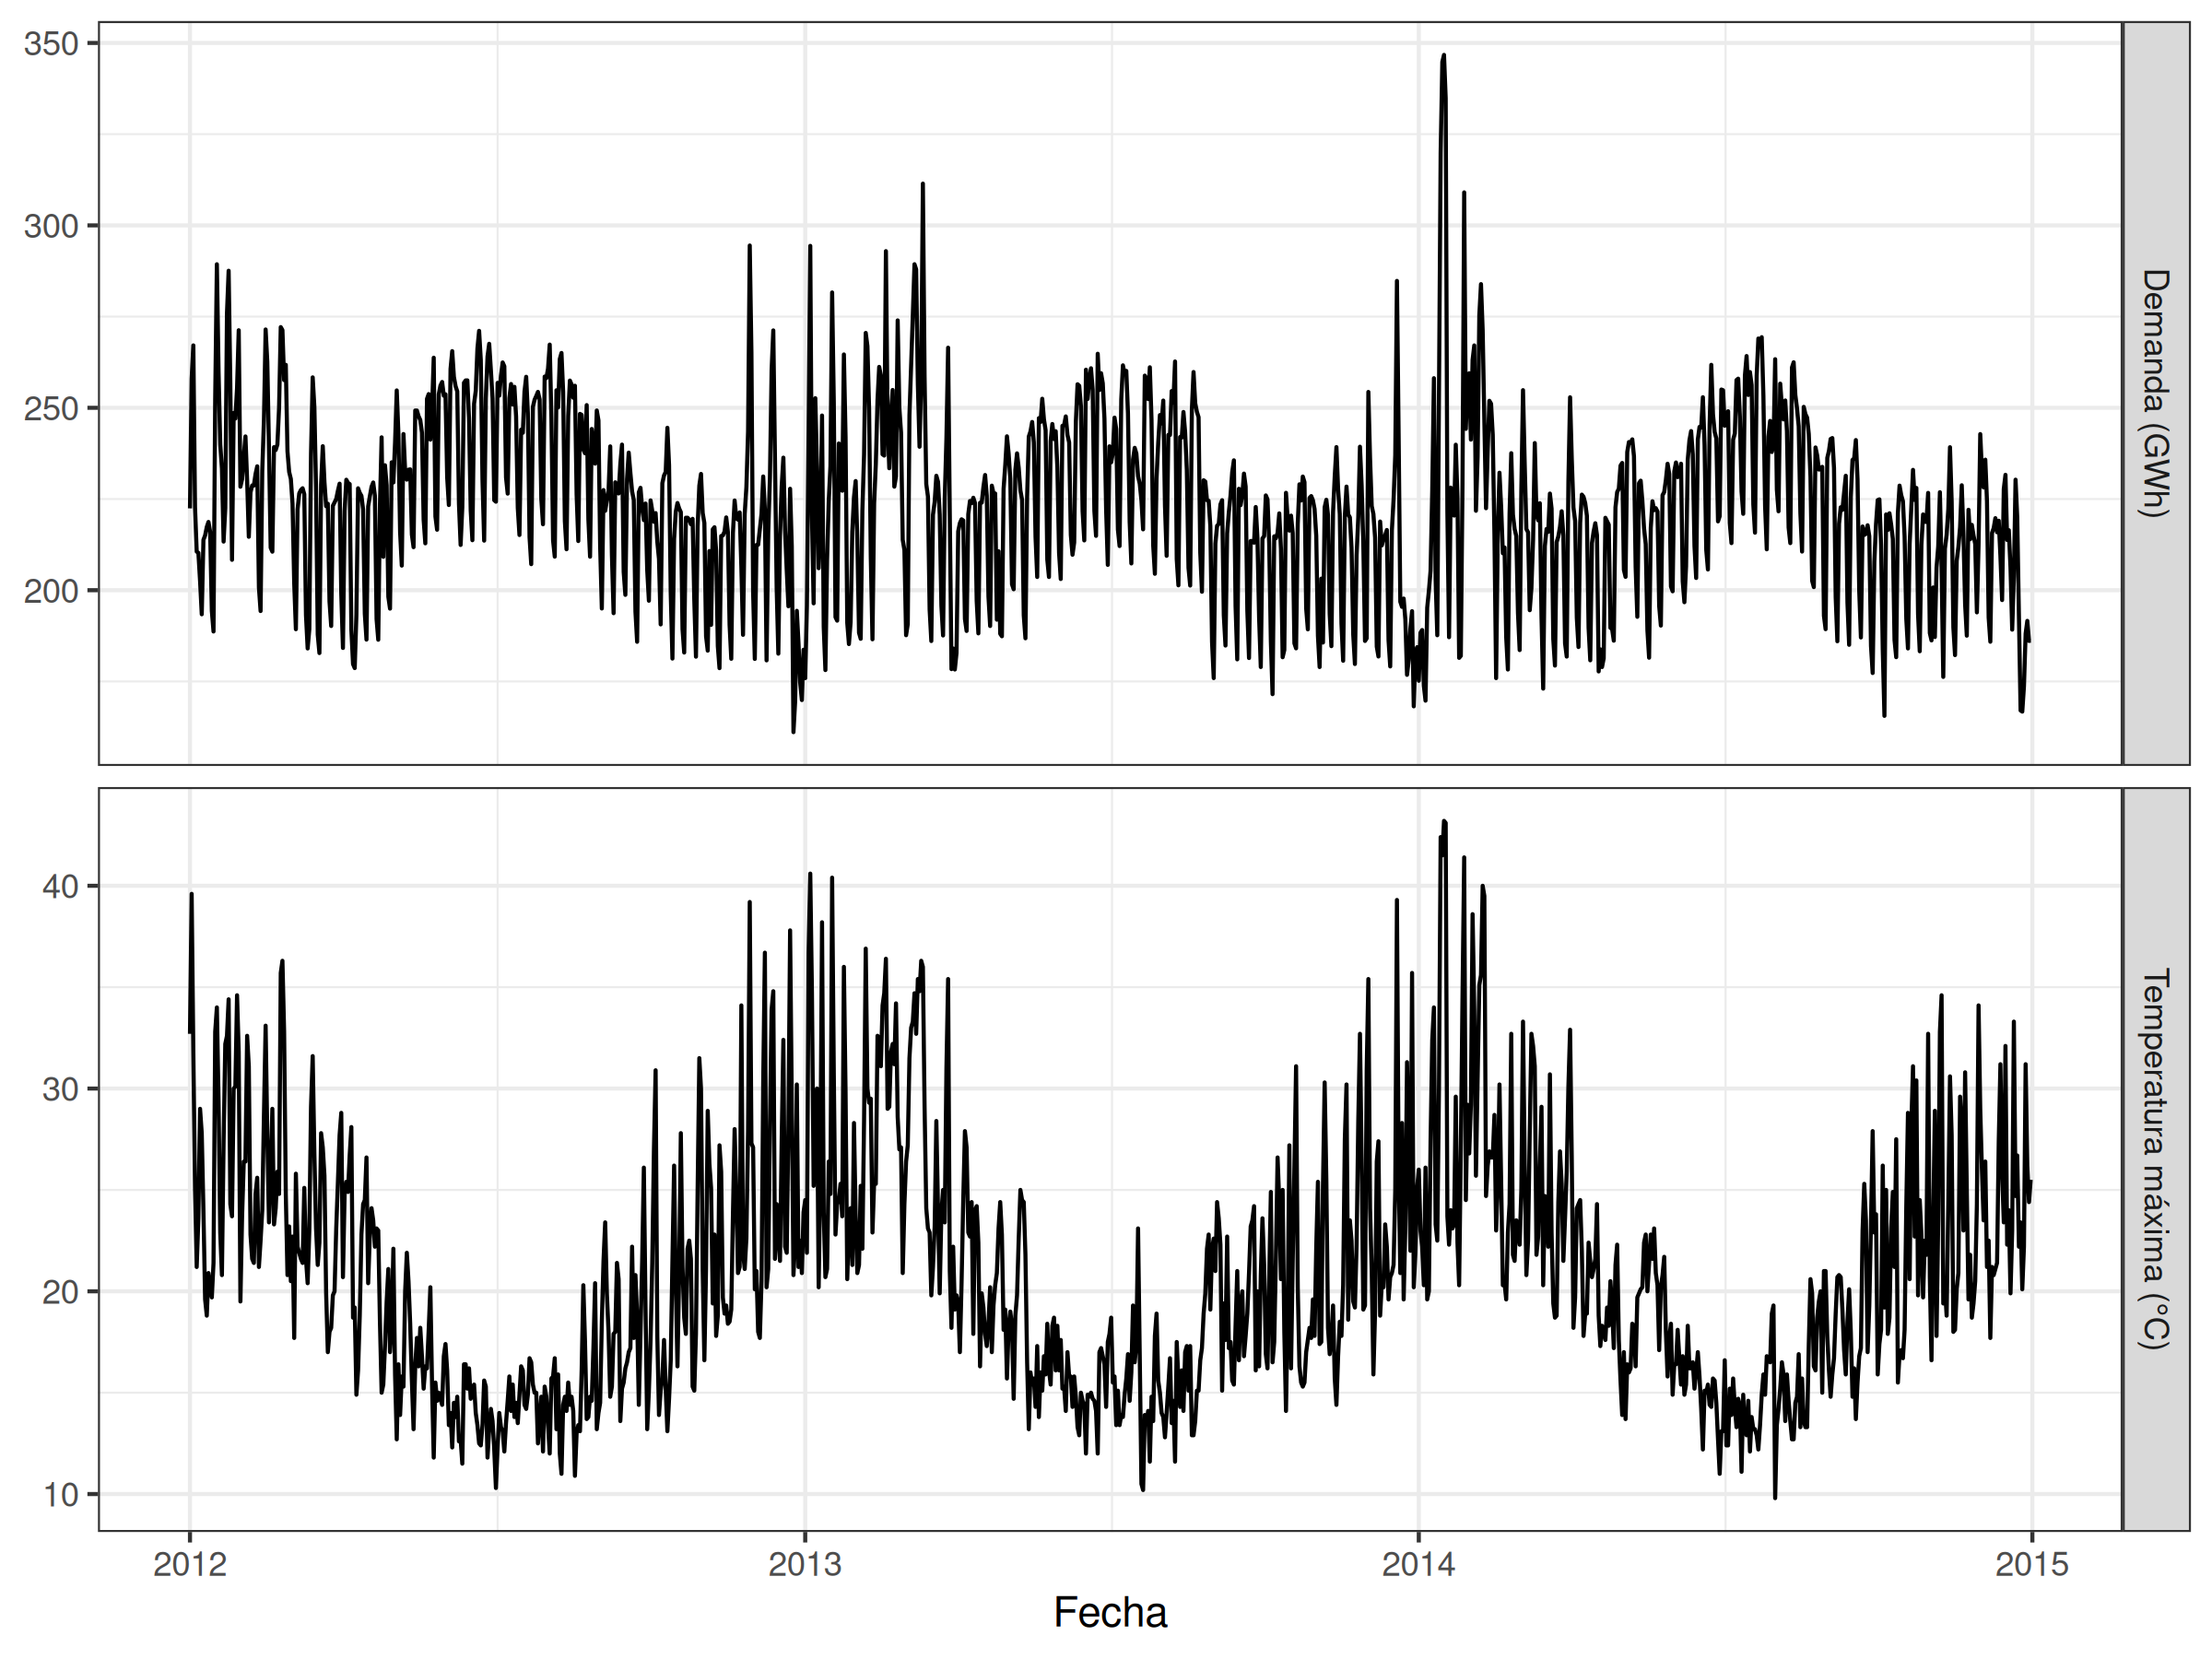

In [3]:
elec |>
  pivot_longer(c(Demand, Temperature)) |>
  mutate(name = recode(name, Demand = "Demanda (GWh)", Temperature = "Temperatura máxima (°C)")) |>
  ggplot(aes(x = Fecha, y = value)) +
  geom_line() +
  facet_grid(name ~ ., scales = "free_y") +
  labs(x = "Fecha", y = NULL)

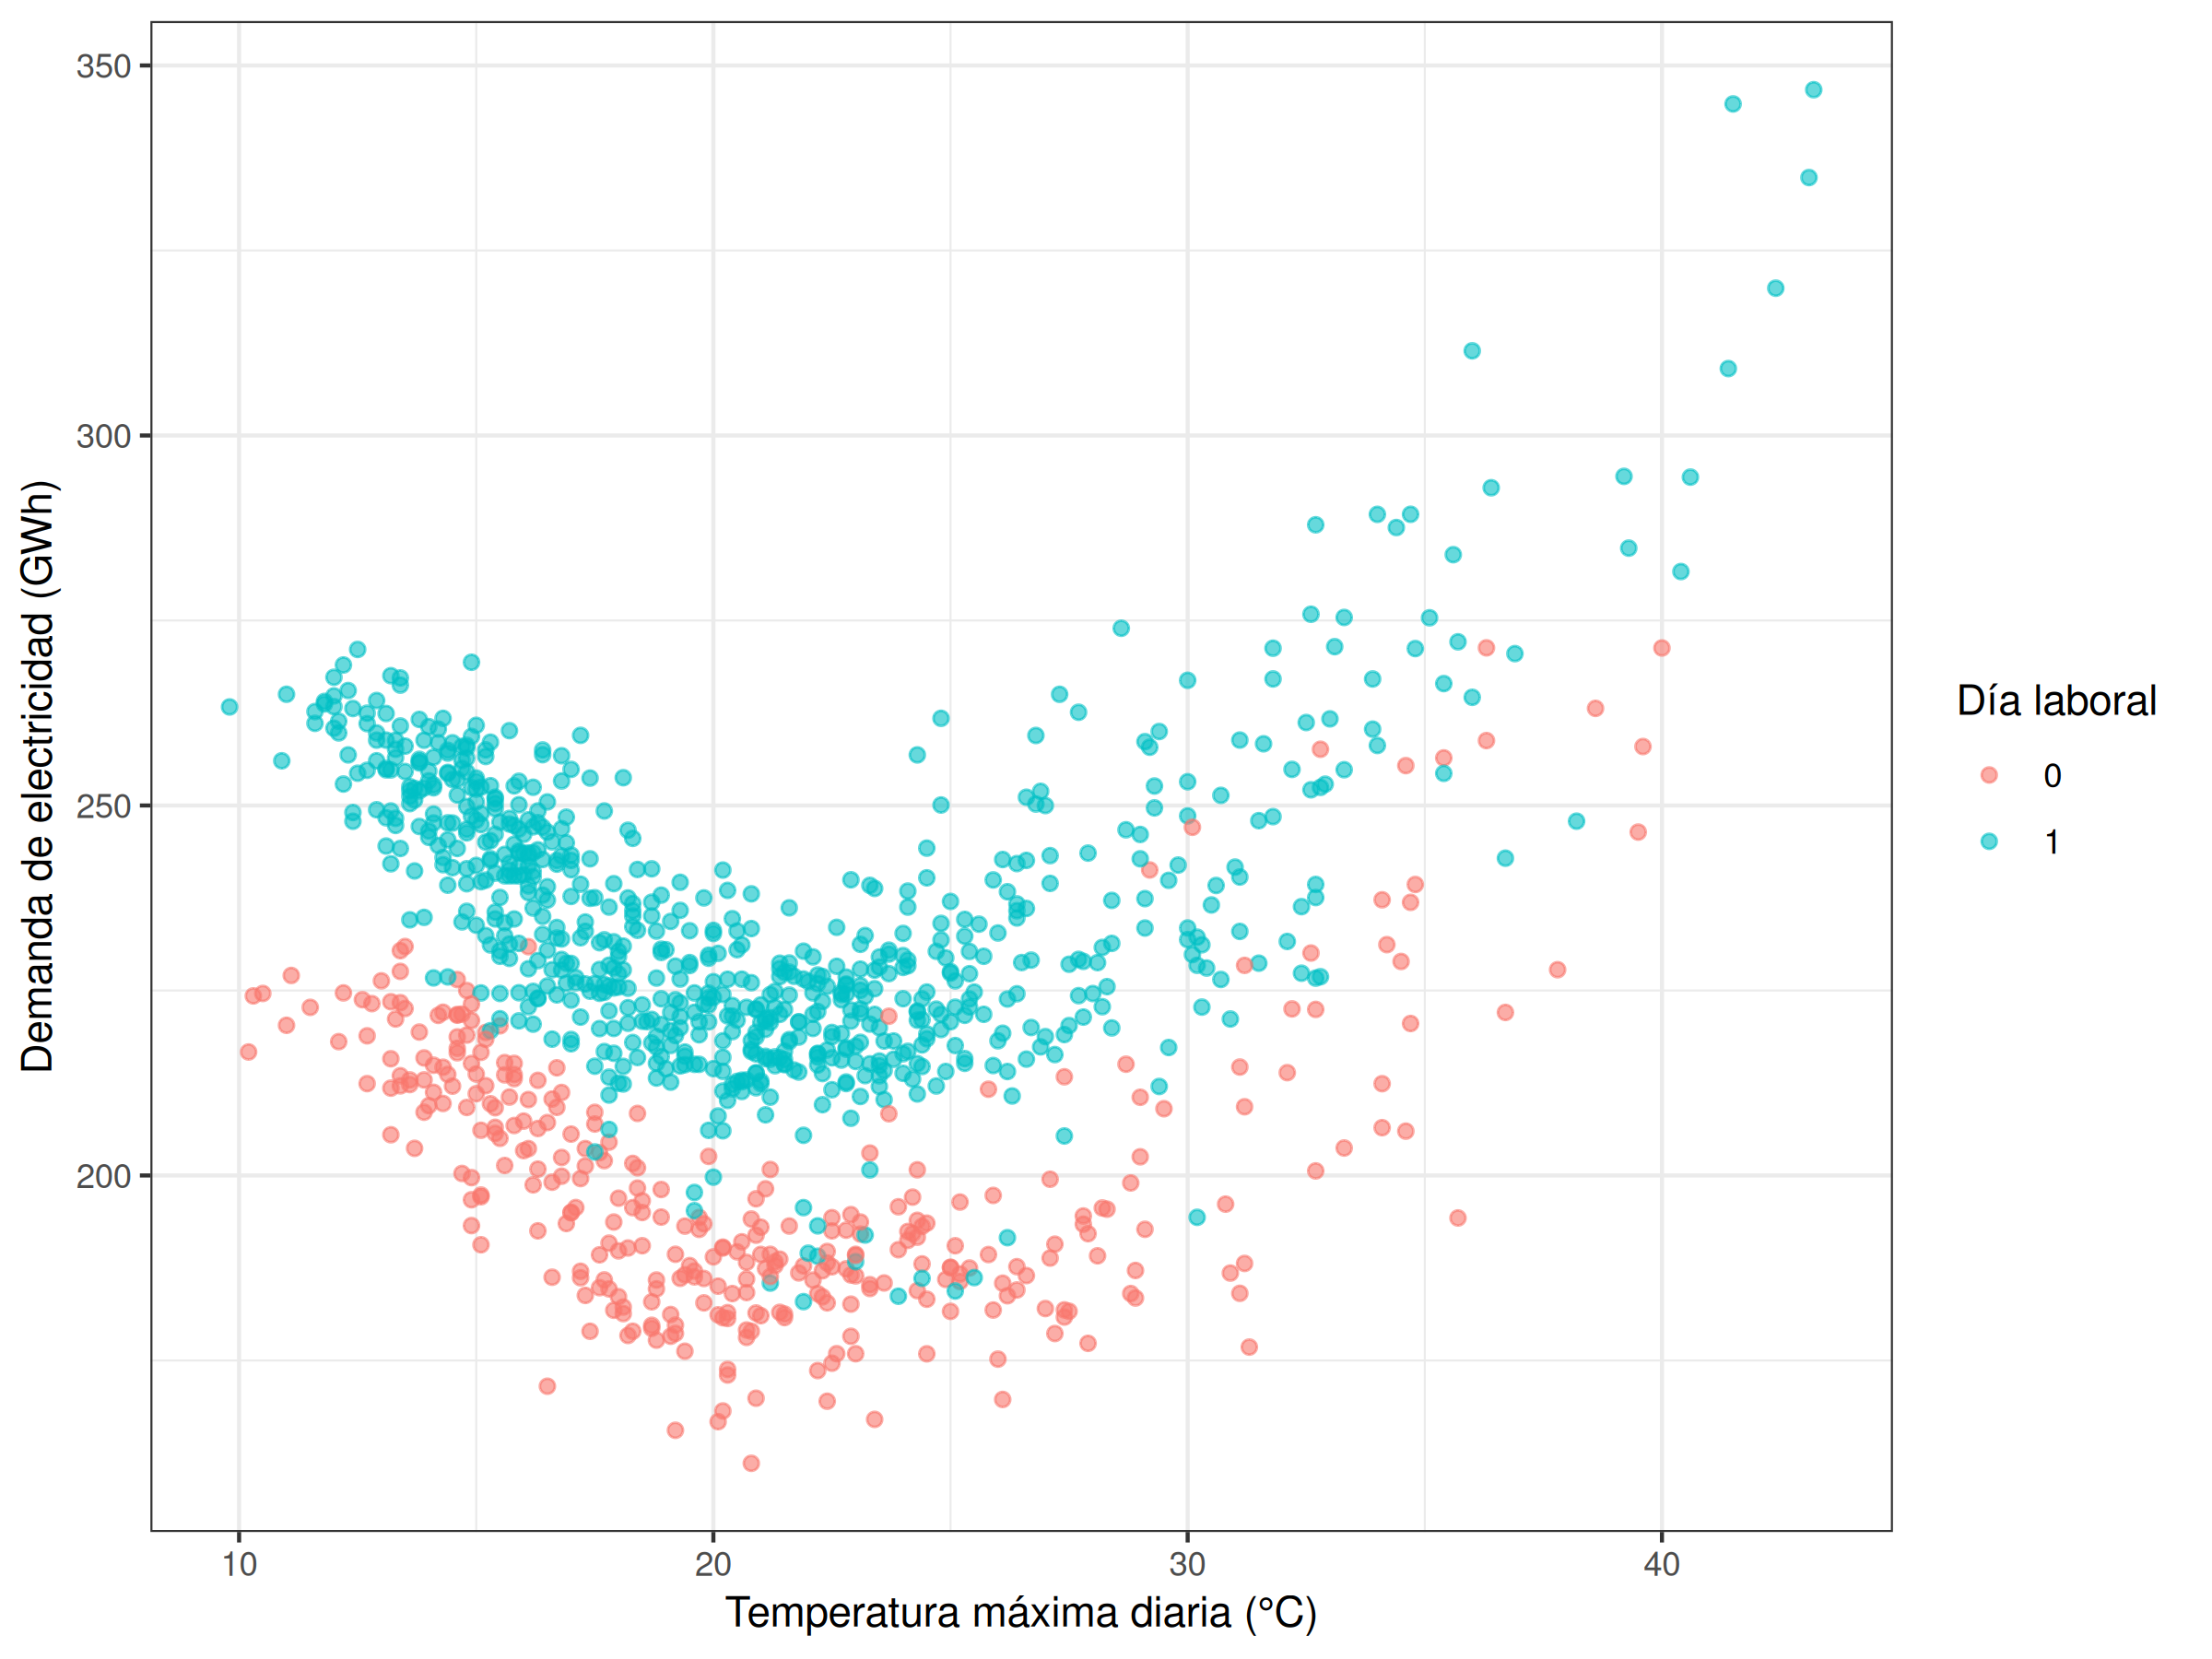

In [4]:
elec |>
  ggplot(aes(x = Temperature, y = Demand, colour = factor(Working_Day))) +
  geom_point(alpha = 0.6) +
  labs(x = "Temperatura máxima diaria (°C)",
       y = "Demanda de electricidad (GWh)",
       colour = "Día laboral")

Si se representa la demanda de electricidad en función de la temperatura, se observa una relación no lineal entre ambas. La demanda aumenta con las temperaturas bajas, por el uso de calefacción, y con las temperaturas altas, por el uso de aire acondicionado. Esta forma de U se puede capturar incluyendo la temperatura y la temperatura al cuadrado como regresoras. Además, los días laborales tienen una demanda mayor que los fines de semana y festivos.

## Conjuntos de entrenamiento y prueba

- Reservamos los últimos 90 días como conjunto de prueba. Ningún modelo usa esos datos durante la estimación, y con ellos medimos el error de pronóstico.

In [5]:
h <- 90   # horizonte de pronóstico en días

train <- elec |> filter(Fecha <= max(Fecha) - h)
test  <- elec |> filter(Fecha >  max(Fecha) - h)

tibble(
  Conjunto = c("Entrenamiento", "Prueba"),
  Inicio   = c(min(train$Fecha), min(test$Fecha)),
  Fin      = c(max(train$Fecha), max(test$Fecha)),
  Dias     = c(nrow(train), nrow(test))
)

Conjunto,Inicio,Fin,Dias
<chr>,<date>,<date>,<int>
Entrenamiento,2012-01-01,2014-10-02,1006
Prueba,2014-10-03,2014-12-31,90


## Modelos

Estimamos cuatro modelos en una sola llamada a `model()`.

- `snaive` es el modelo de referencia **ingenuo estacional**. Pronostica cada día con el valor observado el mismo día de la semana anterior. Un modelo más complejo solo se justifica si pronostica mejor que este.
- `prophet` solo usa la historia de la demanda. Estima la tendencia, la estacionalidad semanal y anual con `season()`, y el efecto de los festivos con `holiday()`. Los festivos se pasan como un `tsibble` con la columna `holiday`, que contiene el nombre del evento.
- `prophet_xreg` agrega como regresoras la temperatura, la temperatura al cuadrado y el indicador de día laboral. El indicador de día laboral ya incluye los festivos, por lo que no se agregan por separado. En `fable.prophet` las regresoras se escriben directamente en la fórmula, pero deben ser columnas de los datos, por eso usamos la columna `Temperature2`.
- `arima_xreg` es un modelo de regresión con errores ARIMA, también llamado regresión dinámica (capítulo 10 de FPP3). Usa las mismas regresoras y agrega términos de Fourier con `fourier(period = "year", K = 4)` para la estacionalidad anual. La estacionalidad semanal queda en la parte estacional de los errores. El valor de K se eligió comparando el AICc de varios modelos, y con `pdq(d = 0)` evitamos que una diferencia elimine los términos de Fourier.

In [6]:
# Festivos en formato tsibble con la columna holiday
festivos <- elec |>
  filter(Holiday) |>
  transmute(holiday = "festivo")

fit <- train |>
  model(
    snaive       = SNAIVE(Demand ~ lag("week")),
    prophet      = prophet(Demand ~ season("week") + season("year") + holiday(festivos)),
    prophet_xreg = prophet(Demand ~ Temperature + Temperature2 + Working_Day +
                             season("week") + season("year")),
    arima_xreg   = ARIMA(Demand ~ Temperature + I(Temperature^2) + Working_Day +
                           fourier(period = "year", K = 4) + pdq(d = 0))
  )

fit

snaive,prophet,prophet_xreg,arima_xreg
<model>,<model>,<model>,<model>
<SNAIVE>,<prophet>,<prophet>,"<LM w/ ARIMA(2,0,2)(2,0,0)[7] errors>"


## Componentes de Prophet

- La función `components()` descompone el ajuste de Prophet en tendencia (`trend`), estacionalidad semanal (`week`) y anual (`year`). La columna `additive_terms` es la suma de todos los efectos aditivos, por lo que el efecto de los festivos o de las regresoras se obtiene restando las dos estacionalidades.
- Para ver mejor cada efecto graficamos los componentes en el tiempo y comparamos la estacionalidad semanal de los modelos en un gráfico aparte.

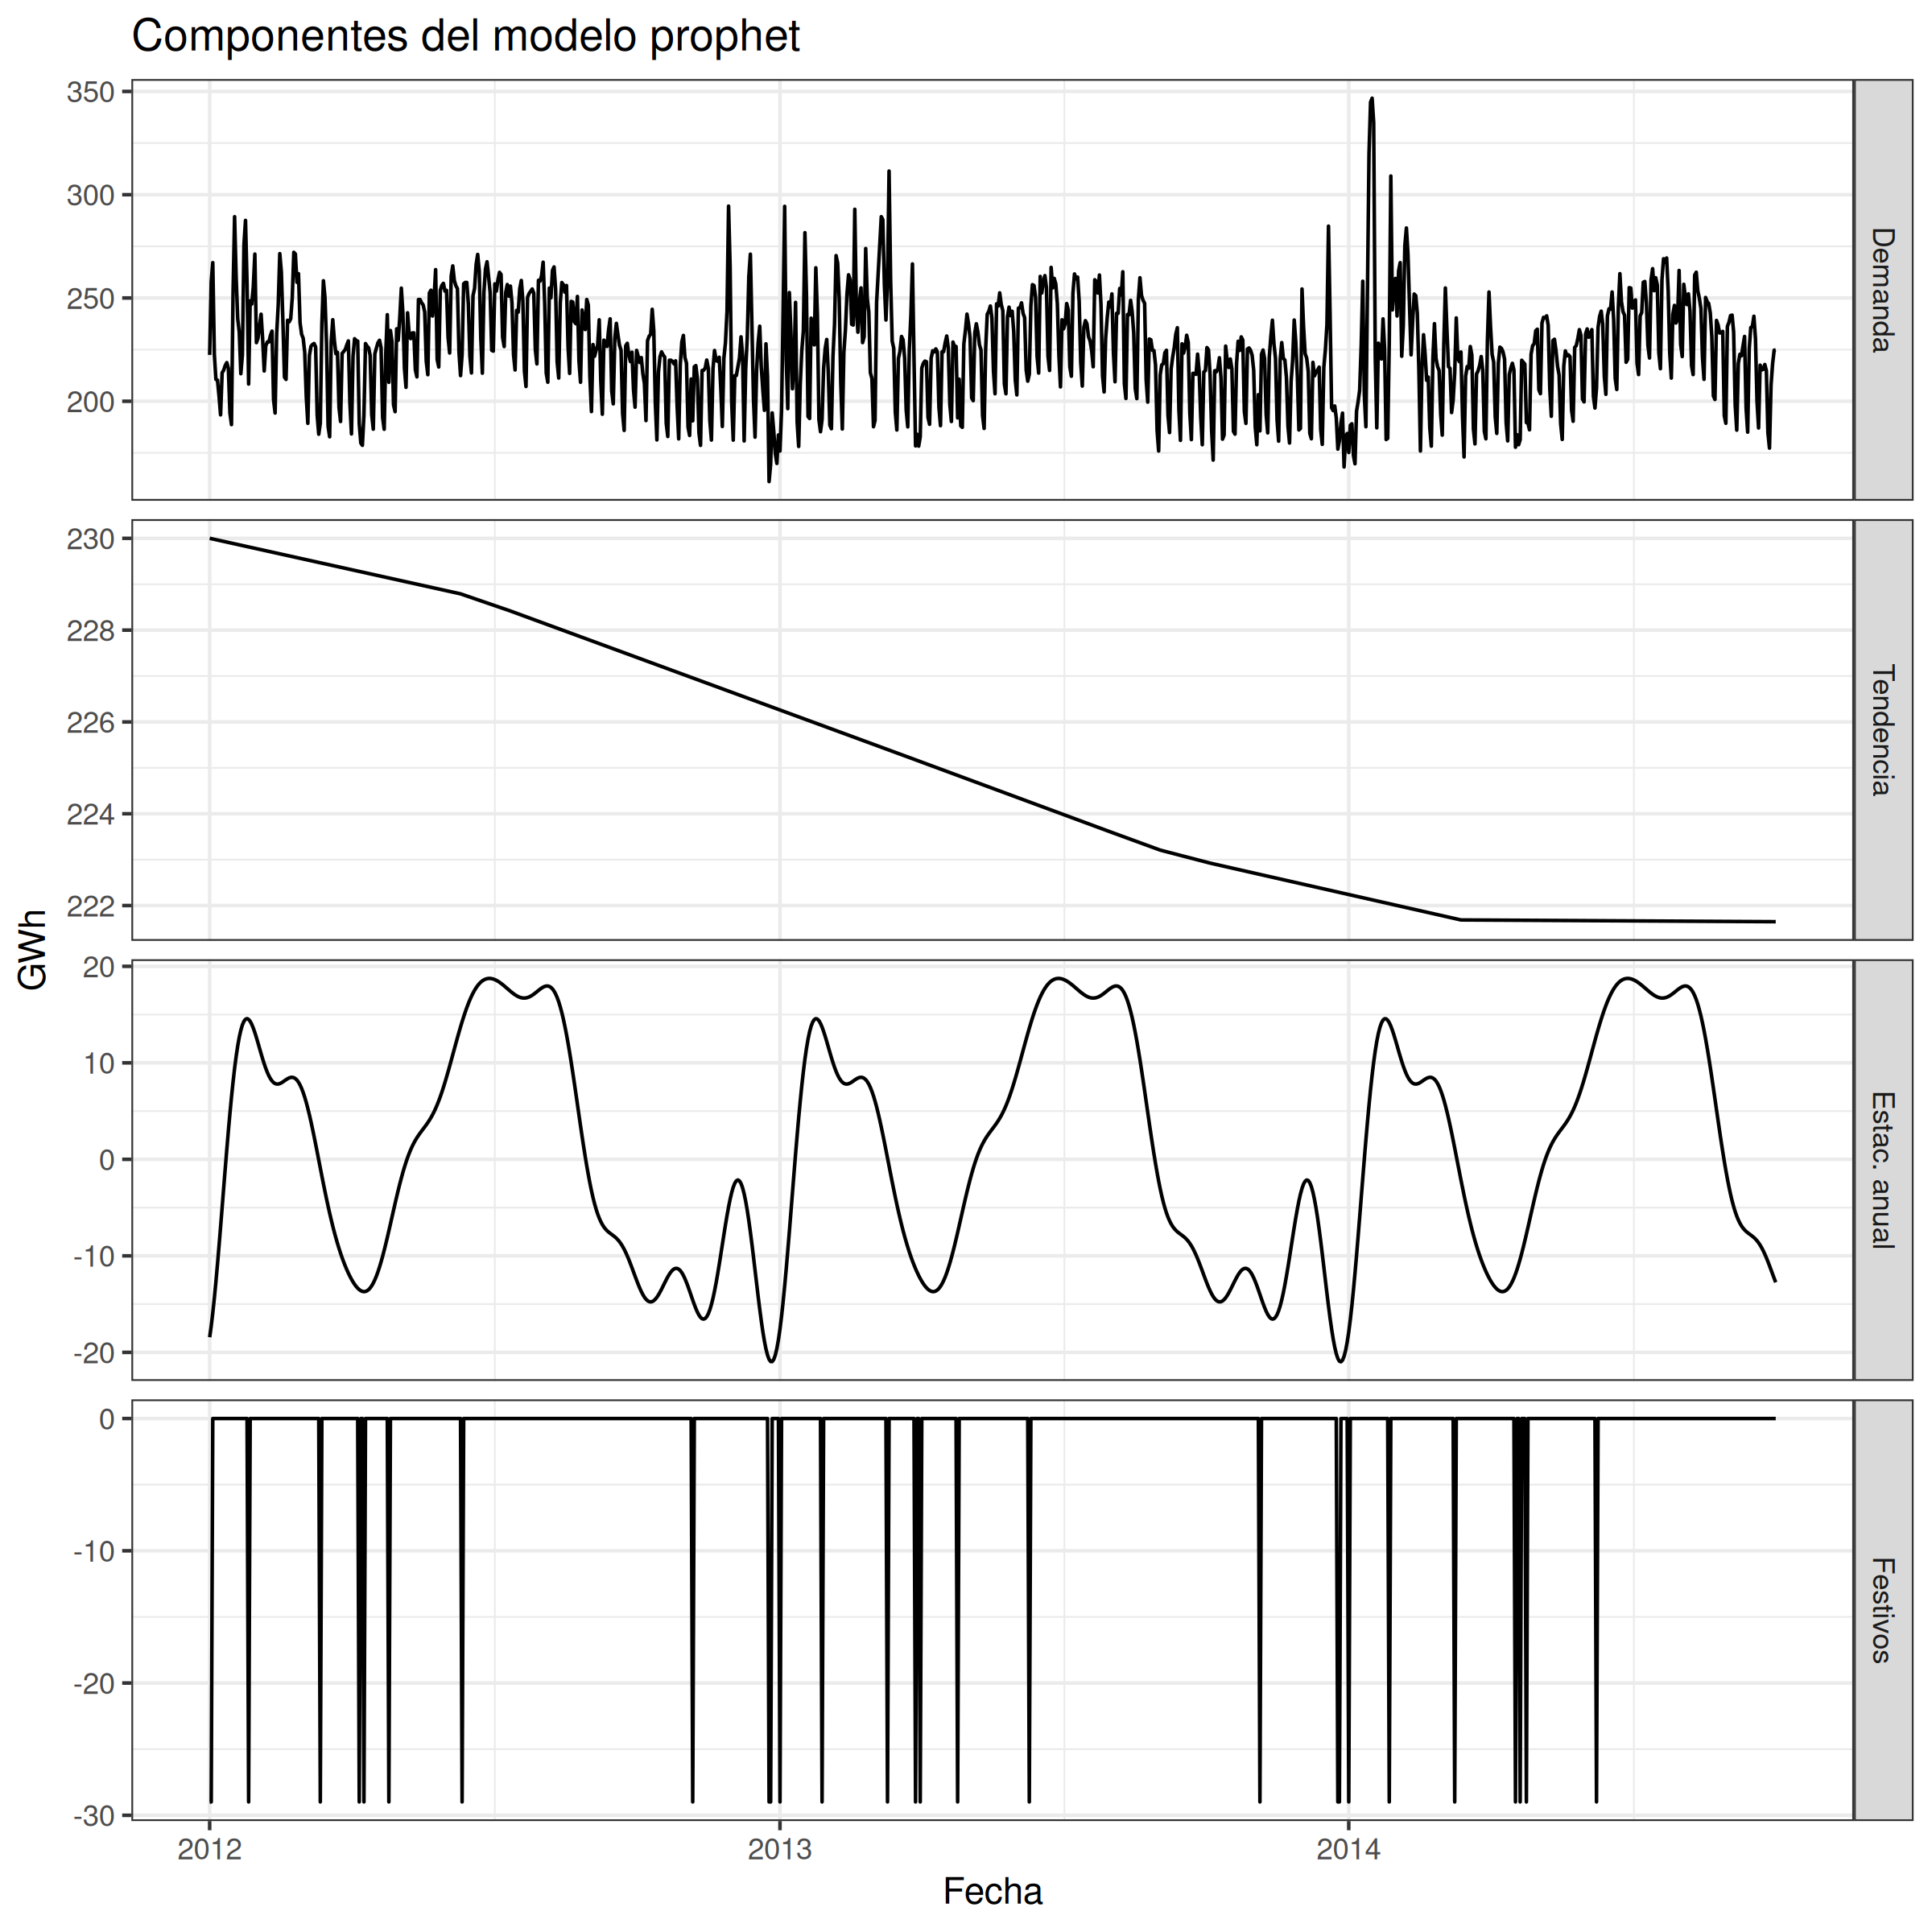

In [7]:
graficar_componentes <- function(modelo, nombre_otros) {
  fit |>
    select(all_of(modelo)) |>
    components() |>
    as_tibble() |>
    mutate(otros = additive_terms - week - year) |>
    select(Fecha, Demanda = Demand, Tendencia = trend, `Estac. anual` = year, otros) |>
    rename(!!nombre_otros := otros) |>
    pivot_longer(-Fecha) |>
    mutate(name = fct_inorder(name)) |>
    ggplot(aes(x = Fecha, y = value)) +
    geom_line() +
    facet_grid(name ~ ., scales = "free_y") +
    labs(x = "Fecha", y = "GWh", title = paste("Componentes del modelo", modelo))
}

options(repr.plot.height = 8)
graficar_componentes("prophet", "Festivos")

**Interpretación de los componentes**

- La tendencia baja lentamente durante el periodo, de unos 230 a unos 222 GWh, una vez descontados los efectos estacionales.
- La estacionalidad anual muestra una demanda más alta en el invierno austral (junio a agosto), por la calefacción, un pico menor en el verano (febrero), por el aire acondicionado, y una demanda más baja en la primavera y en las vacaciones de fin de año.
- El componente de festivos es constante, porque el modelo estima un solo efecto para todos los festivos. Un día festivo tiene unos 29 GWh menos de demanda que un día normal.

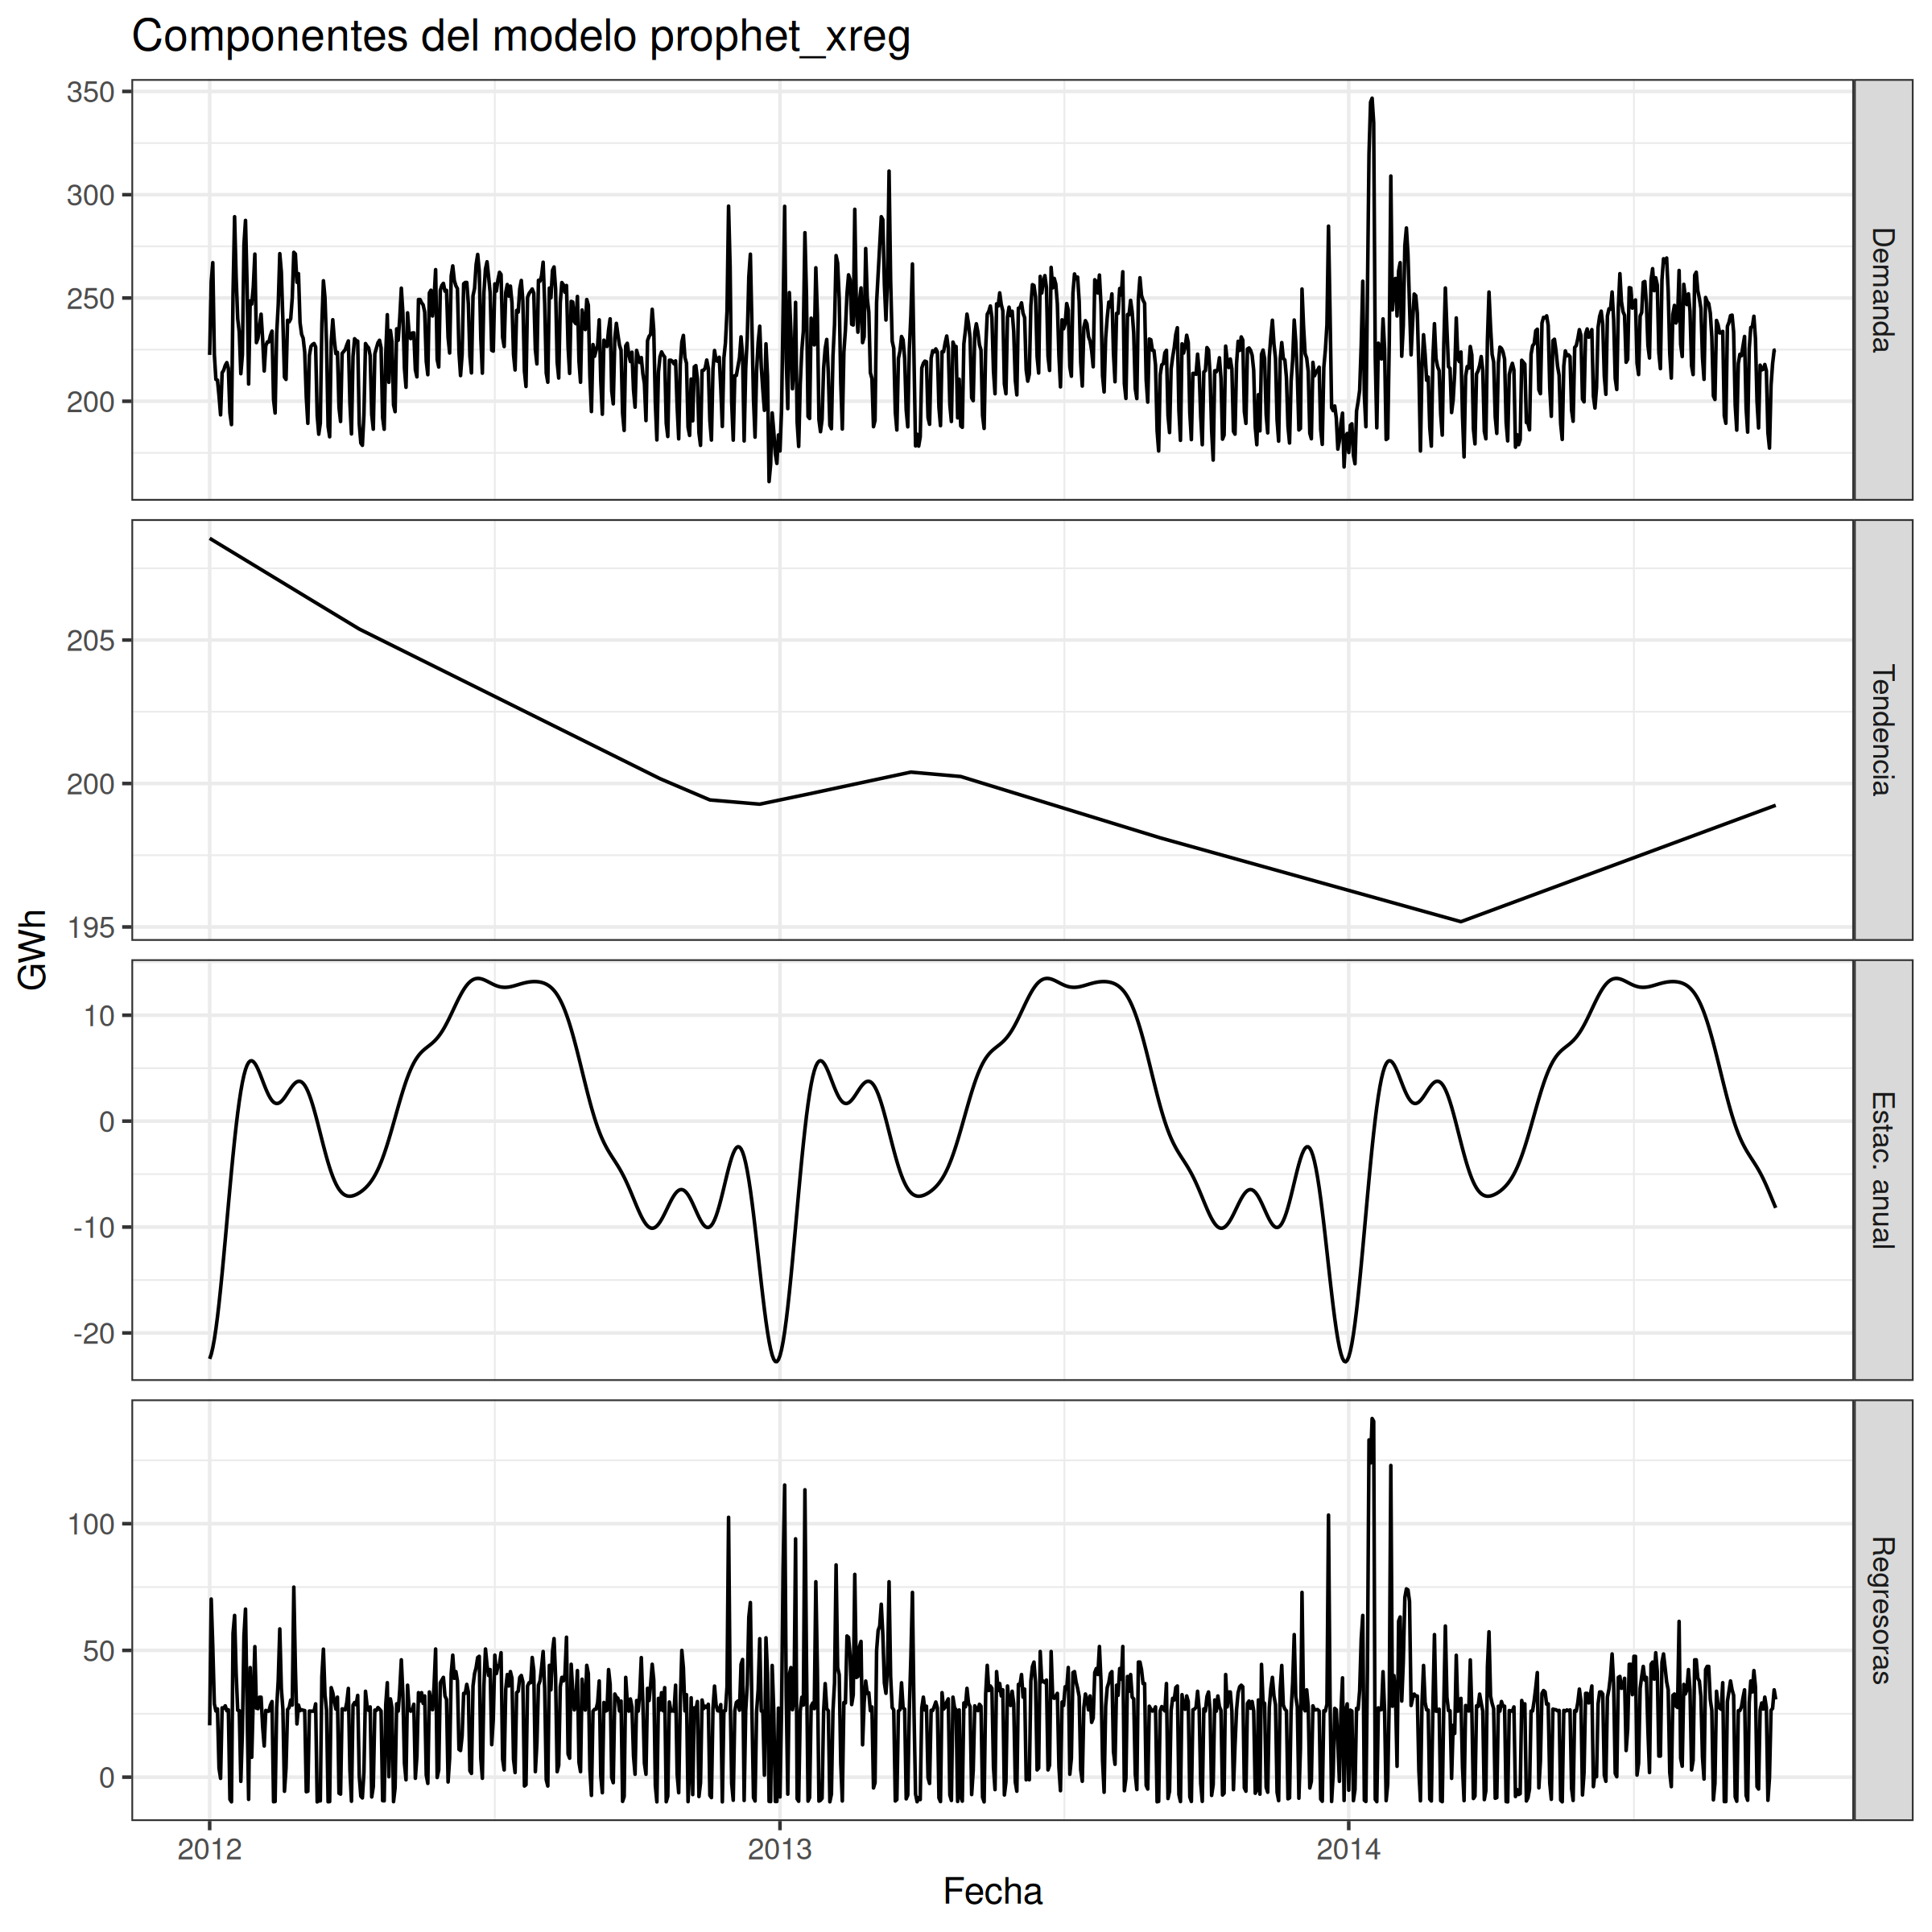

In [8]:
graficar_componentes("prophet_xreg", "Regresoras")

**Interpretación de los componentes**

- El componente de regresoras reúne el efecto de la temperatura y del día laboral. Sus valores más altos aparecen en las olas de calor del verano, como la de mediados de enero de 2014, cuando la temperatura explica más de 120 GWh de demanda adicional.
- La tendencia ahora tiene un nivel más bajo, porque parte del nivel de la demanda queda en el componente de regresoras.
- La estacionalidad anual conserva una forma parecida a la del modelo sin regresoras, aunque con una amplitud algo menor. La temperatura máxima no explica todo el patrón del año, y por ejemplo la fuerte caída de la demanda en las vacaciones de fin de año sigue apareciendo en este componente.

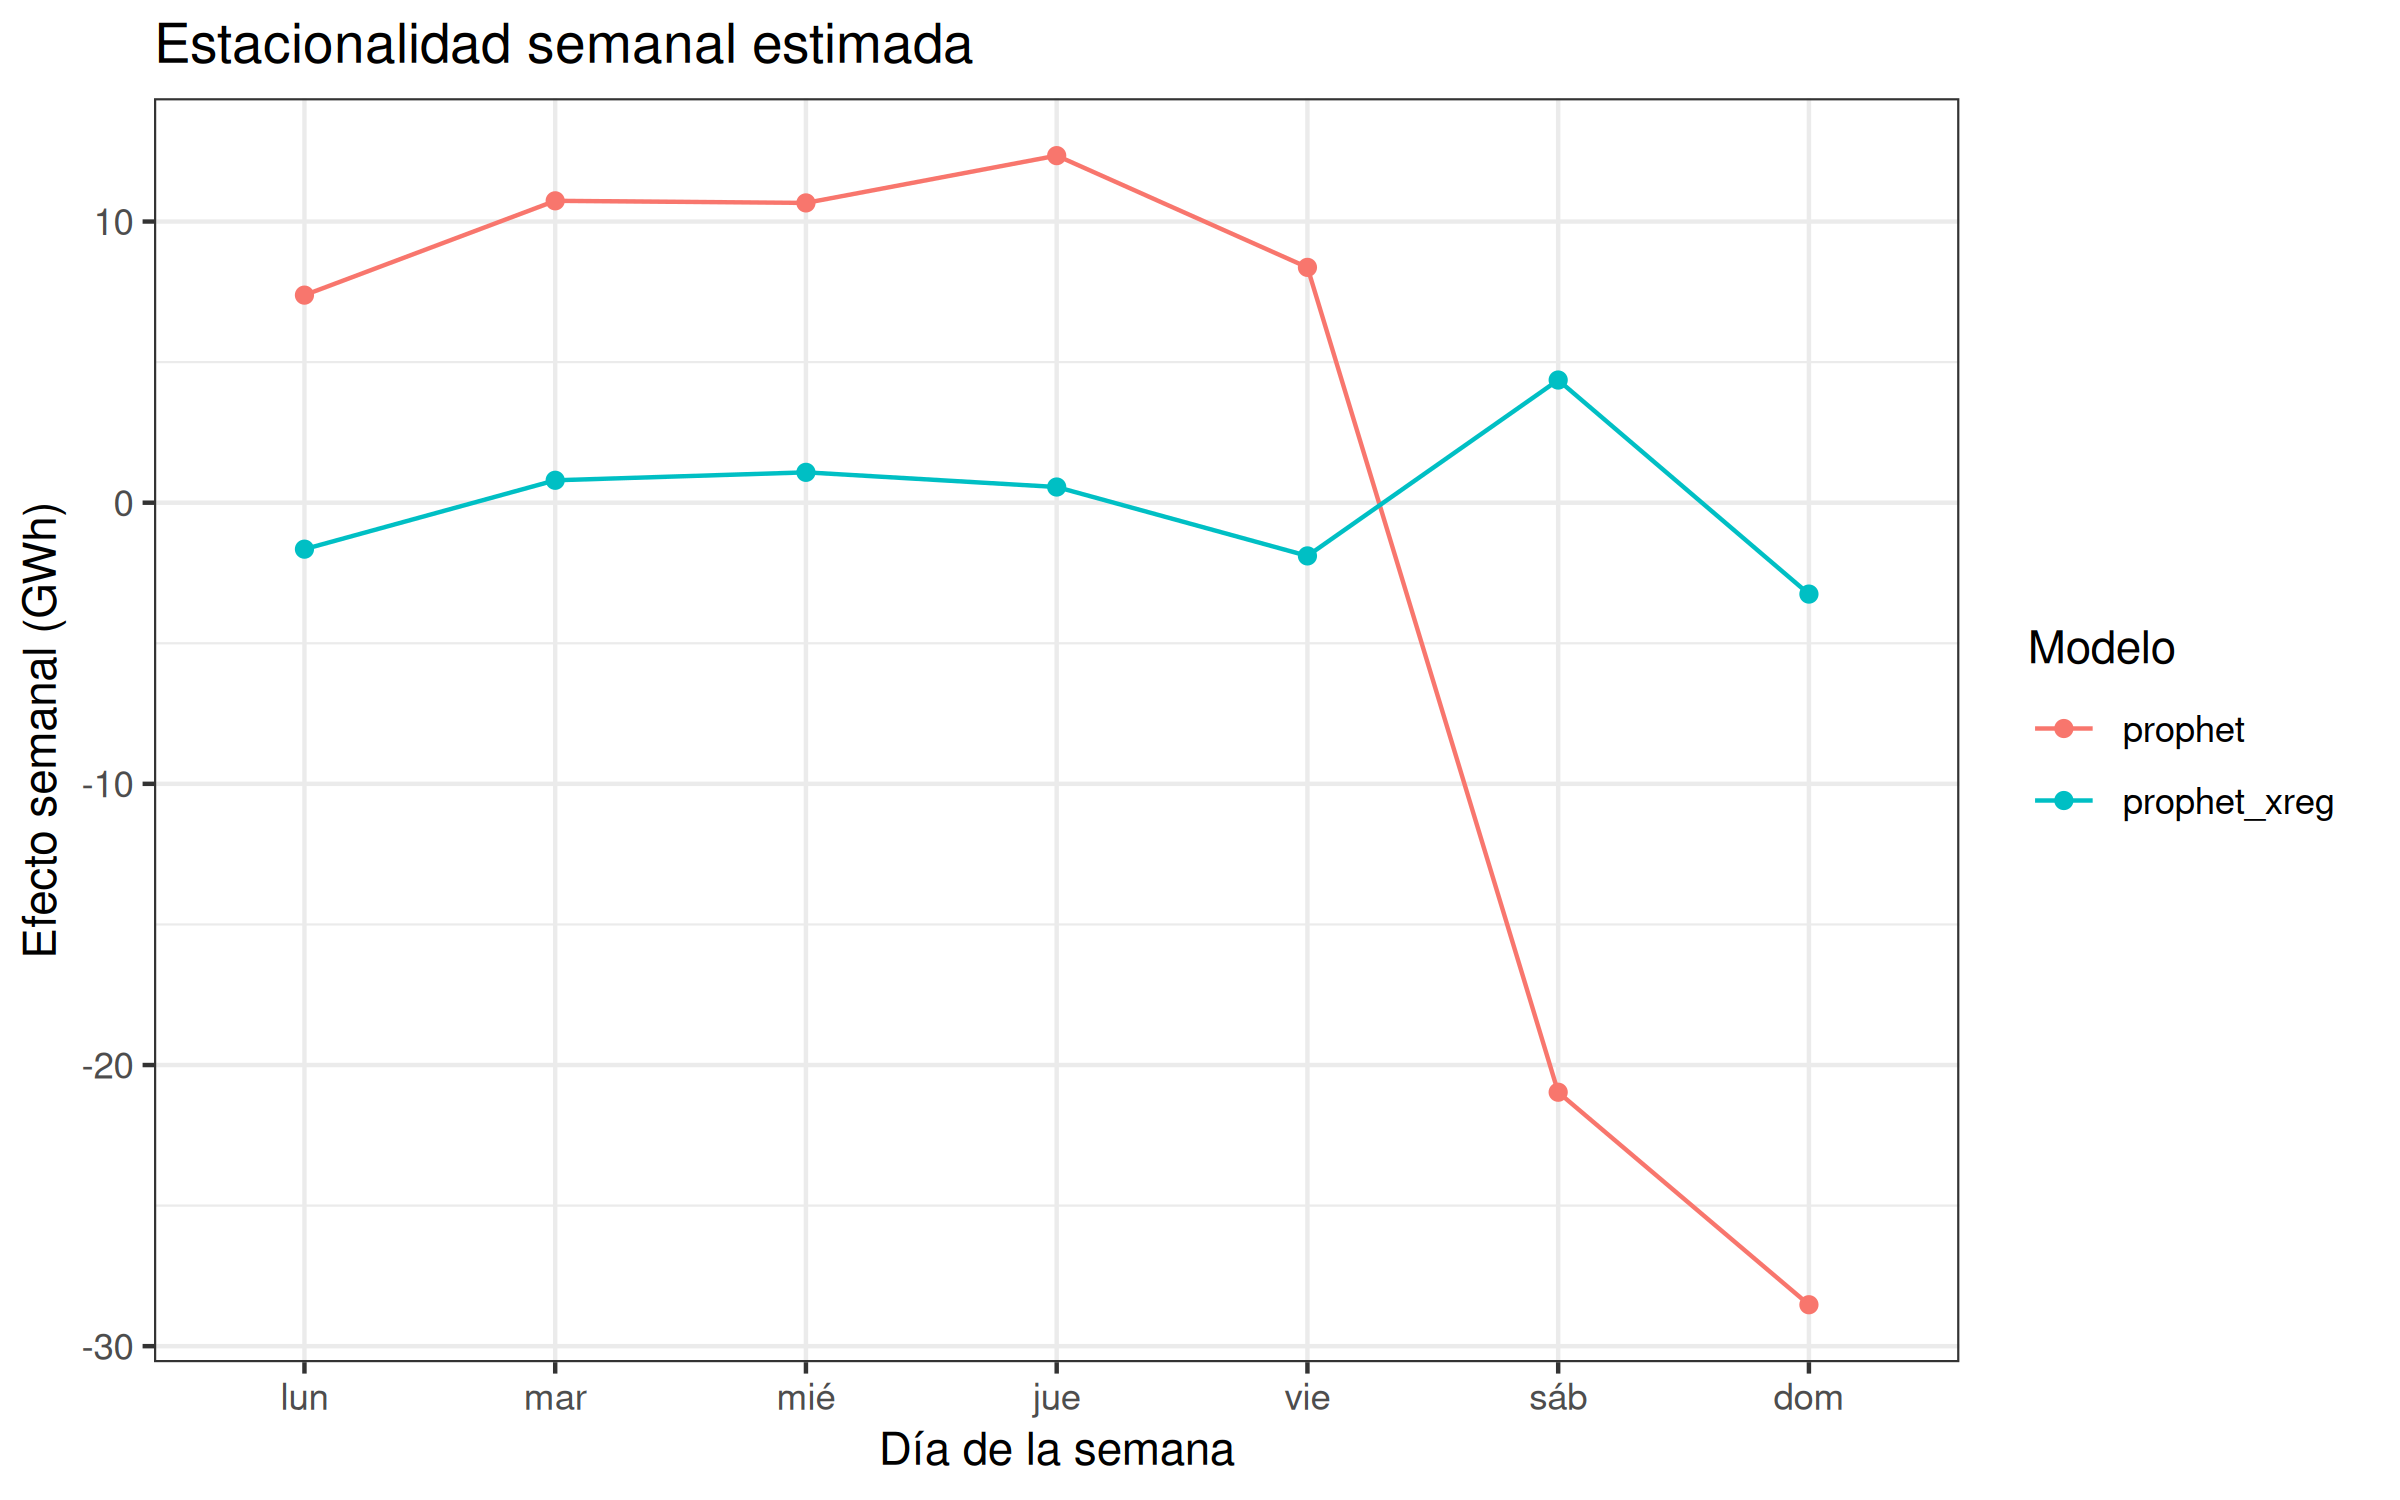

In [9]:
options(repr.plot.height = 5)
fit |>
  select(prophet, prophet_xreg) |>
  components() |>
  as_tibble() |>
  mutate(Dia = wday(Fecha, label = TRUE, week_start = 1)) |>
  group_by(.model, Dia) |>
  summarise(week = mean(week), .groups = "drop") |>
  ggplot(aes(x = Dia, y = week, colour = .model, group = .model)) +
  geom_line() +
  geom_point() +
  labs(x = "Día de la semana", y = "Efecto semanal (GWh)", colour = "Modelo",
       title = "Estacionalidad semanal estimada")
options(repr.plot.height = 6)

- En el modelo sin regresoras la estacionalidad semanal es muy marcada. Un domingo tiene cerca de 40 GWh menos de demanda que un día entre semana.
- En el modelo con regresoras la estacionalidad semanal casi desaparece, porque el indicador de día laboral ya captura la diferencia entre los días de la semana y los fines de semana.

## Regresión con errores ARIMA

- La función `report()` muestra los coeficientes de las regresoras y el modelo ARIMA que eligió `ARIMA()` para los errores.

In [10]:
fit |>
  select(arima_xreg) |>
  report()

Series: Demand 
Model: LM w/ ARIMA(2,0,2)(2,0,0)[7] errors 

Coefficients:
         ar1      ar2      ma1     ma2    sar1    sar2  Temperature
      1.6567  -0.6998  -0.9982  0.1019  0.1846  0.2222      -7.6826
s.e.  0.0534   0.0427   0.0687  0.0547  0.0339  0.0327       0.3089
      I(Temperature^2)  Working_Day  fourier(period = "year", K = 4)C1_365
                0.1811      32.3448                               -10.2394
s.e.            0.0062       0.7112                                 1.3220
      fourier(period = "year", K = 4)S1_365
                                     2.7861
s.e.                                 1.2649
      fourier(period = "year", K = 4)C2_365
                                     5.5591
s.e.                                 1.2140
      fourier(period = "year", K = 4)S2_365
                                     4.7953
s.e.                                 1.2309
      fourier(period = "year", K = 4)C3_365
                                    -3.0257
s.e.        

**Interpretación**

- `ARIMA()` eligió un modelo $ARIMA(2,0,2)(2,0,0)_7$ para los errores. La parte estacional con periodo 7 recoge la dependencia que queda entre días de la misma semana.
- Los coeficientes de la temperatura (−7.68) y de la temperatura al cuadrado (0.181) describen la forma de U del gráfico de dispersión. La demanda mínima se alcanza con una temperatura de $7.68 / (2 \times 0.181) \approx 21$ °C, y la demanda aumenta cuando la temperatura se aleja de ese valor.
- Un día laboral tiene en promedio 32.3 GWh más de demanda que un fin de semana o un festivo con la misma temperatura.
- Los términos de Fourier de orden bajo son significativos, lo que confirma que existe una estacionalidad anual que la temperatura no explica.

## Diagnóstico de los residuos

- Un buen modelo de pronóstico deja residuos sin autocorrelación. Revisamos los residuos de los dos modelos con regresoras con `gg_tsresiduals()` y la prueba de Ljung-Box.

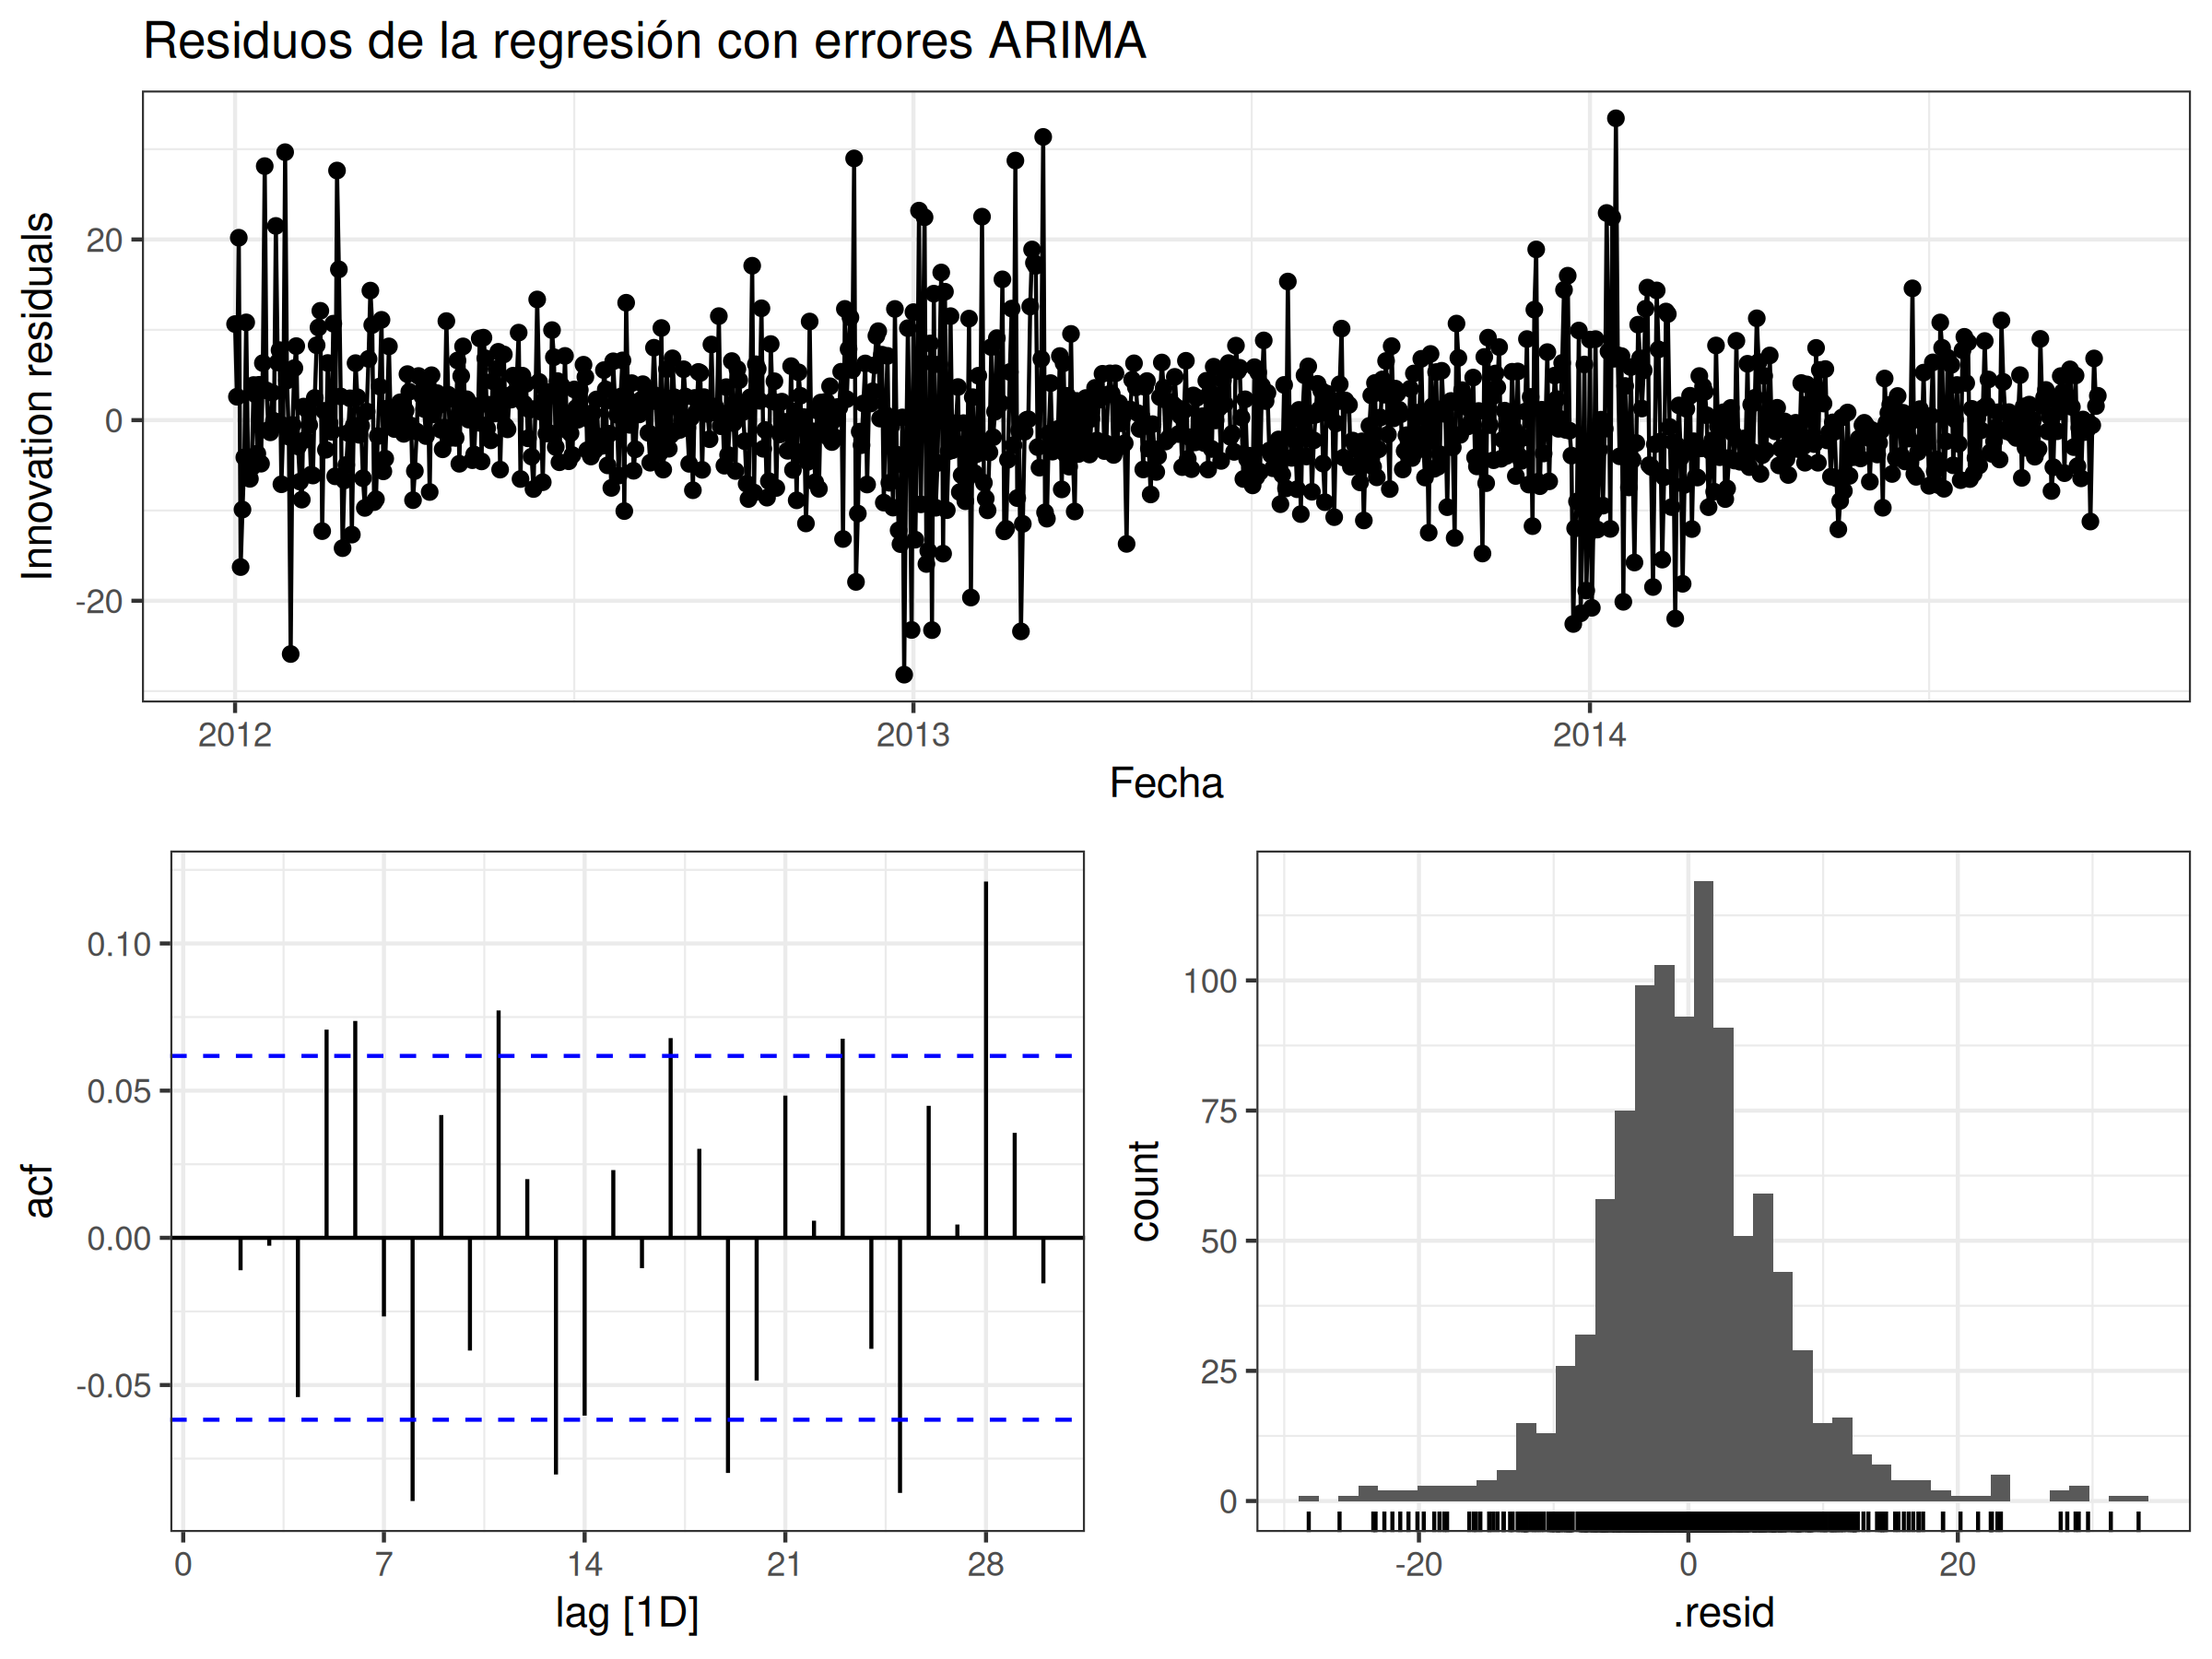

In [11]:
fit |>
  select(arima_xreg) |>
  gg_tsresiduals() +
  labs(title = "Residuos de la regresión con errores ARIMA")

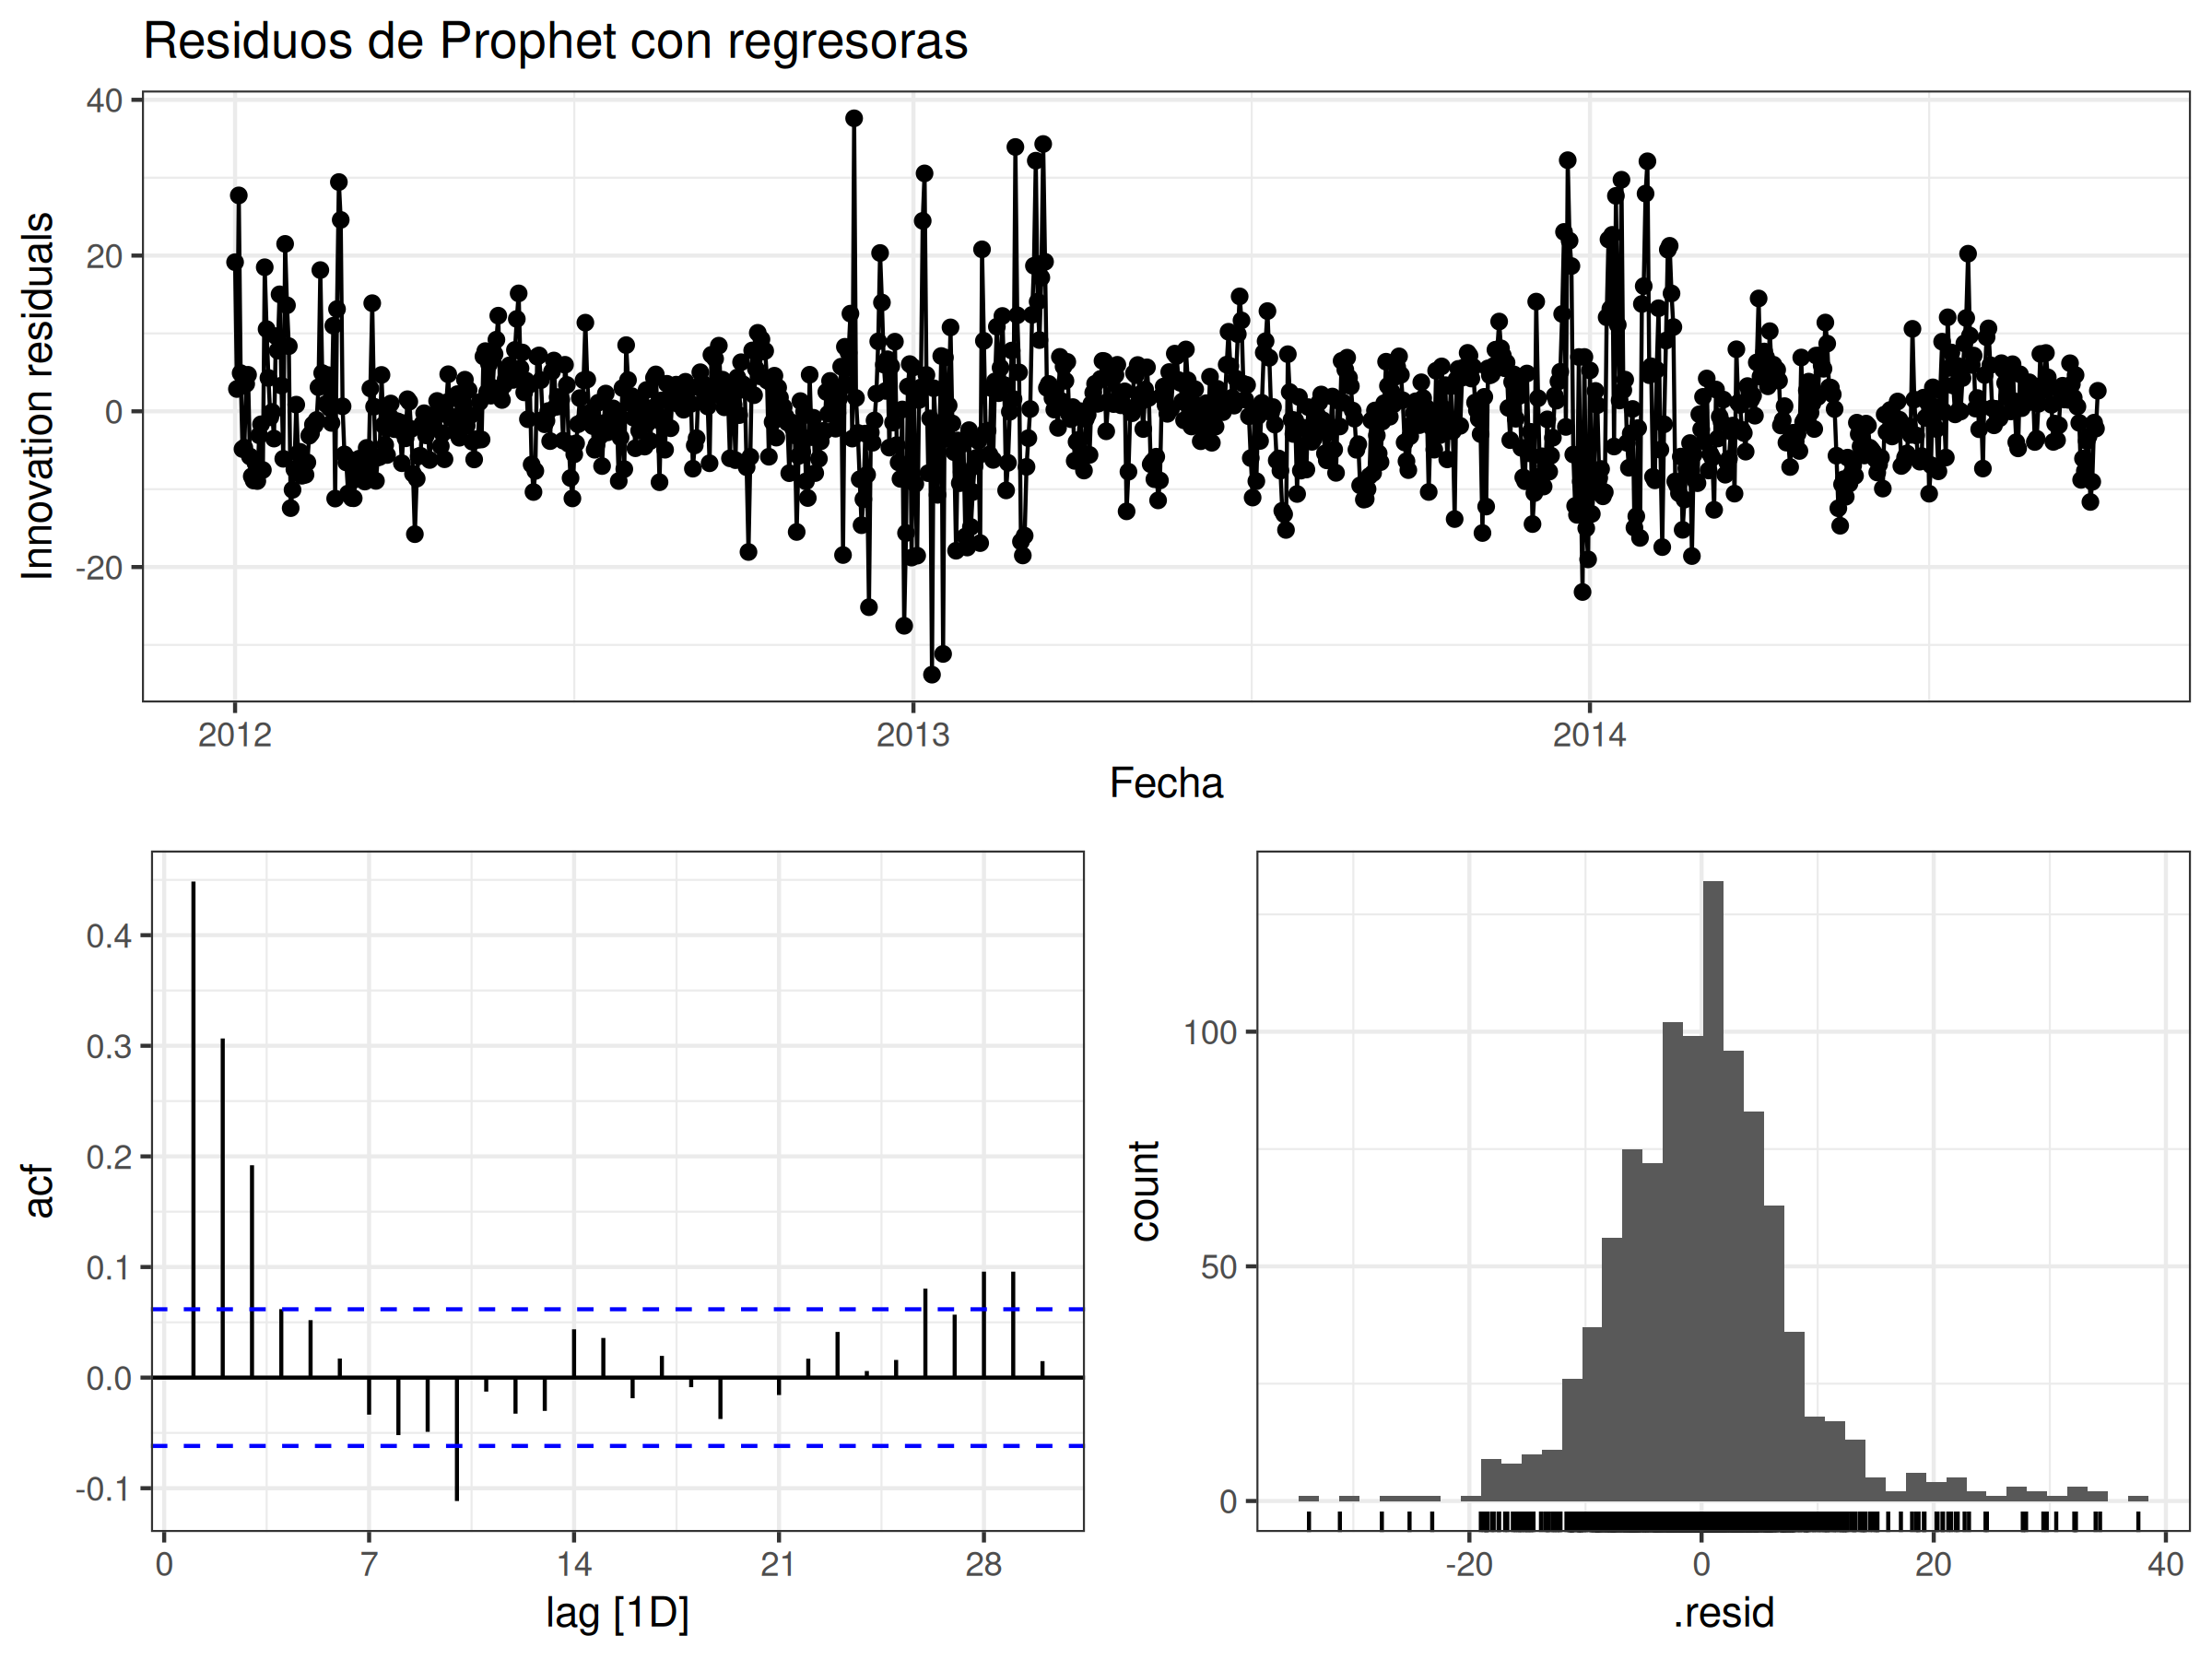

In [12]:
fit |>
  select(prophet_xreg) |>
  gg_tsresiduals() +
  labs(title = "Residuos de Prophet con regresoras")

In [13]:
augment(fit) |>
  filter(.model %in% c("prophet_xreg", "arima_xreg")) |>
  features(.innov, ljung_box, lag = 14)

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
arima_xreg,42.58797,9.968176e-05
prophet_xreg,365.24271,0.000000e+00


**Interpretación**

- Los residuos de la regresión con errores ARIMA tienen pocas autocorrelaciones fuera de las bandas y todas son pequeñas, aunque la prueba de Ljung-Box rechaza que sean ruido blanco. Esto también ocurre en el ejemplo de la demanda diaria del capítulo 10 de FPP3. Los pronósticos puntuales siguen siendo útiles, pero los intervalos de predicción pueden ser algo más angostos de lo que deberían.
- Los residuos de Prophet tienen una autocorrelación fuerte en los primeros rezagos (0.45 en el rezago 1). Prophet no modela la dependencia entre días consecutivos, de modo que si un día la demanda fue mayor que la esperada, es probable que al día siguiente también lo sea. Esa información se pierde en el pronóstico.
- Los dos modelos tienen residuos grandes en los veranos, cuando las olas de calor generan picos de demanda que el modelo no alcanza a reproducir.

## Pronóstico del conjunto de prueba

- Para pronosticar con regresoras, `forecast()` necesita los valores de cada regresora en las fechas que se pronostican, que se pasan con `new_data`. Aquí usamos la temperatura observada en el periodo de prueba, lo que se conoce como **pronóstico ex post**. En la práctica la temperatura futura no se conoce y habría que usar el pronóstico del clima, lo que se conoce como pronóstico ex ante, y el error real sería algo mayor.

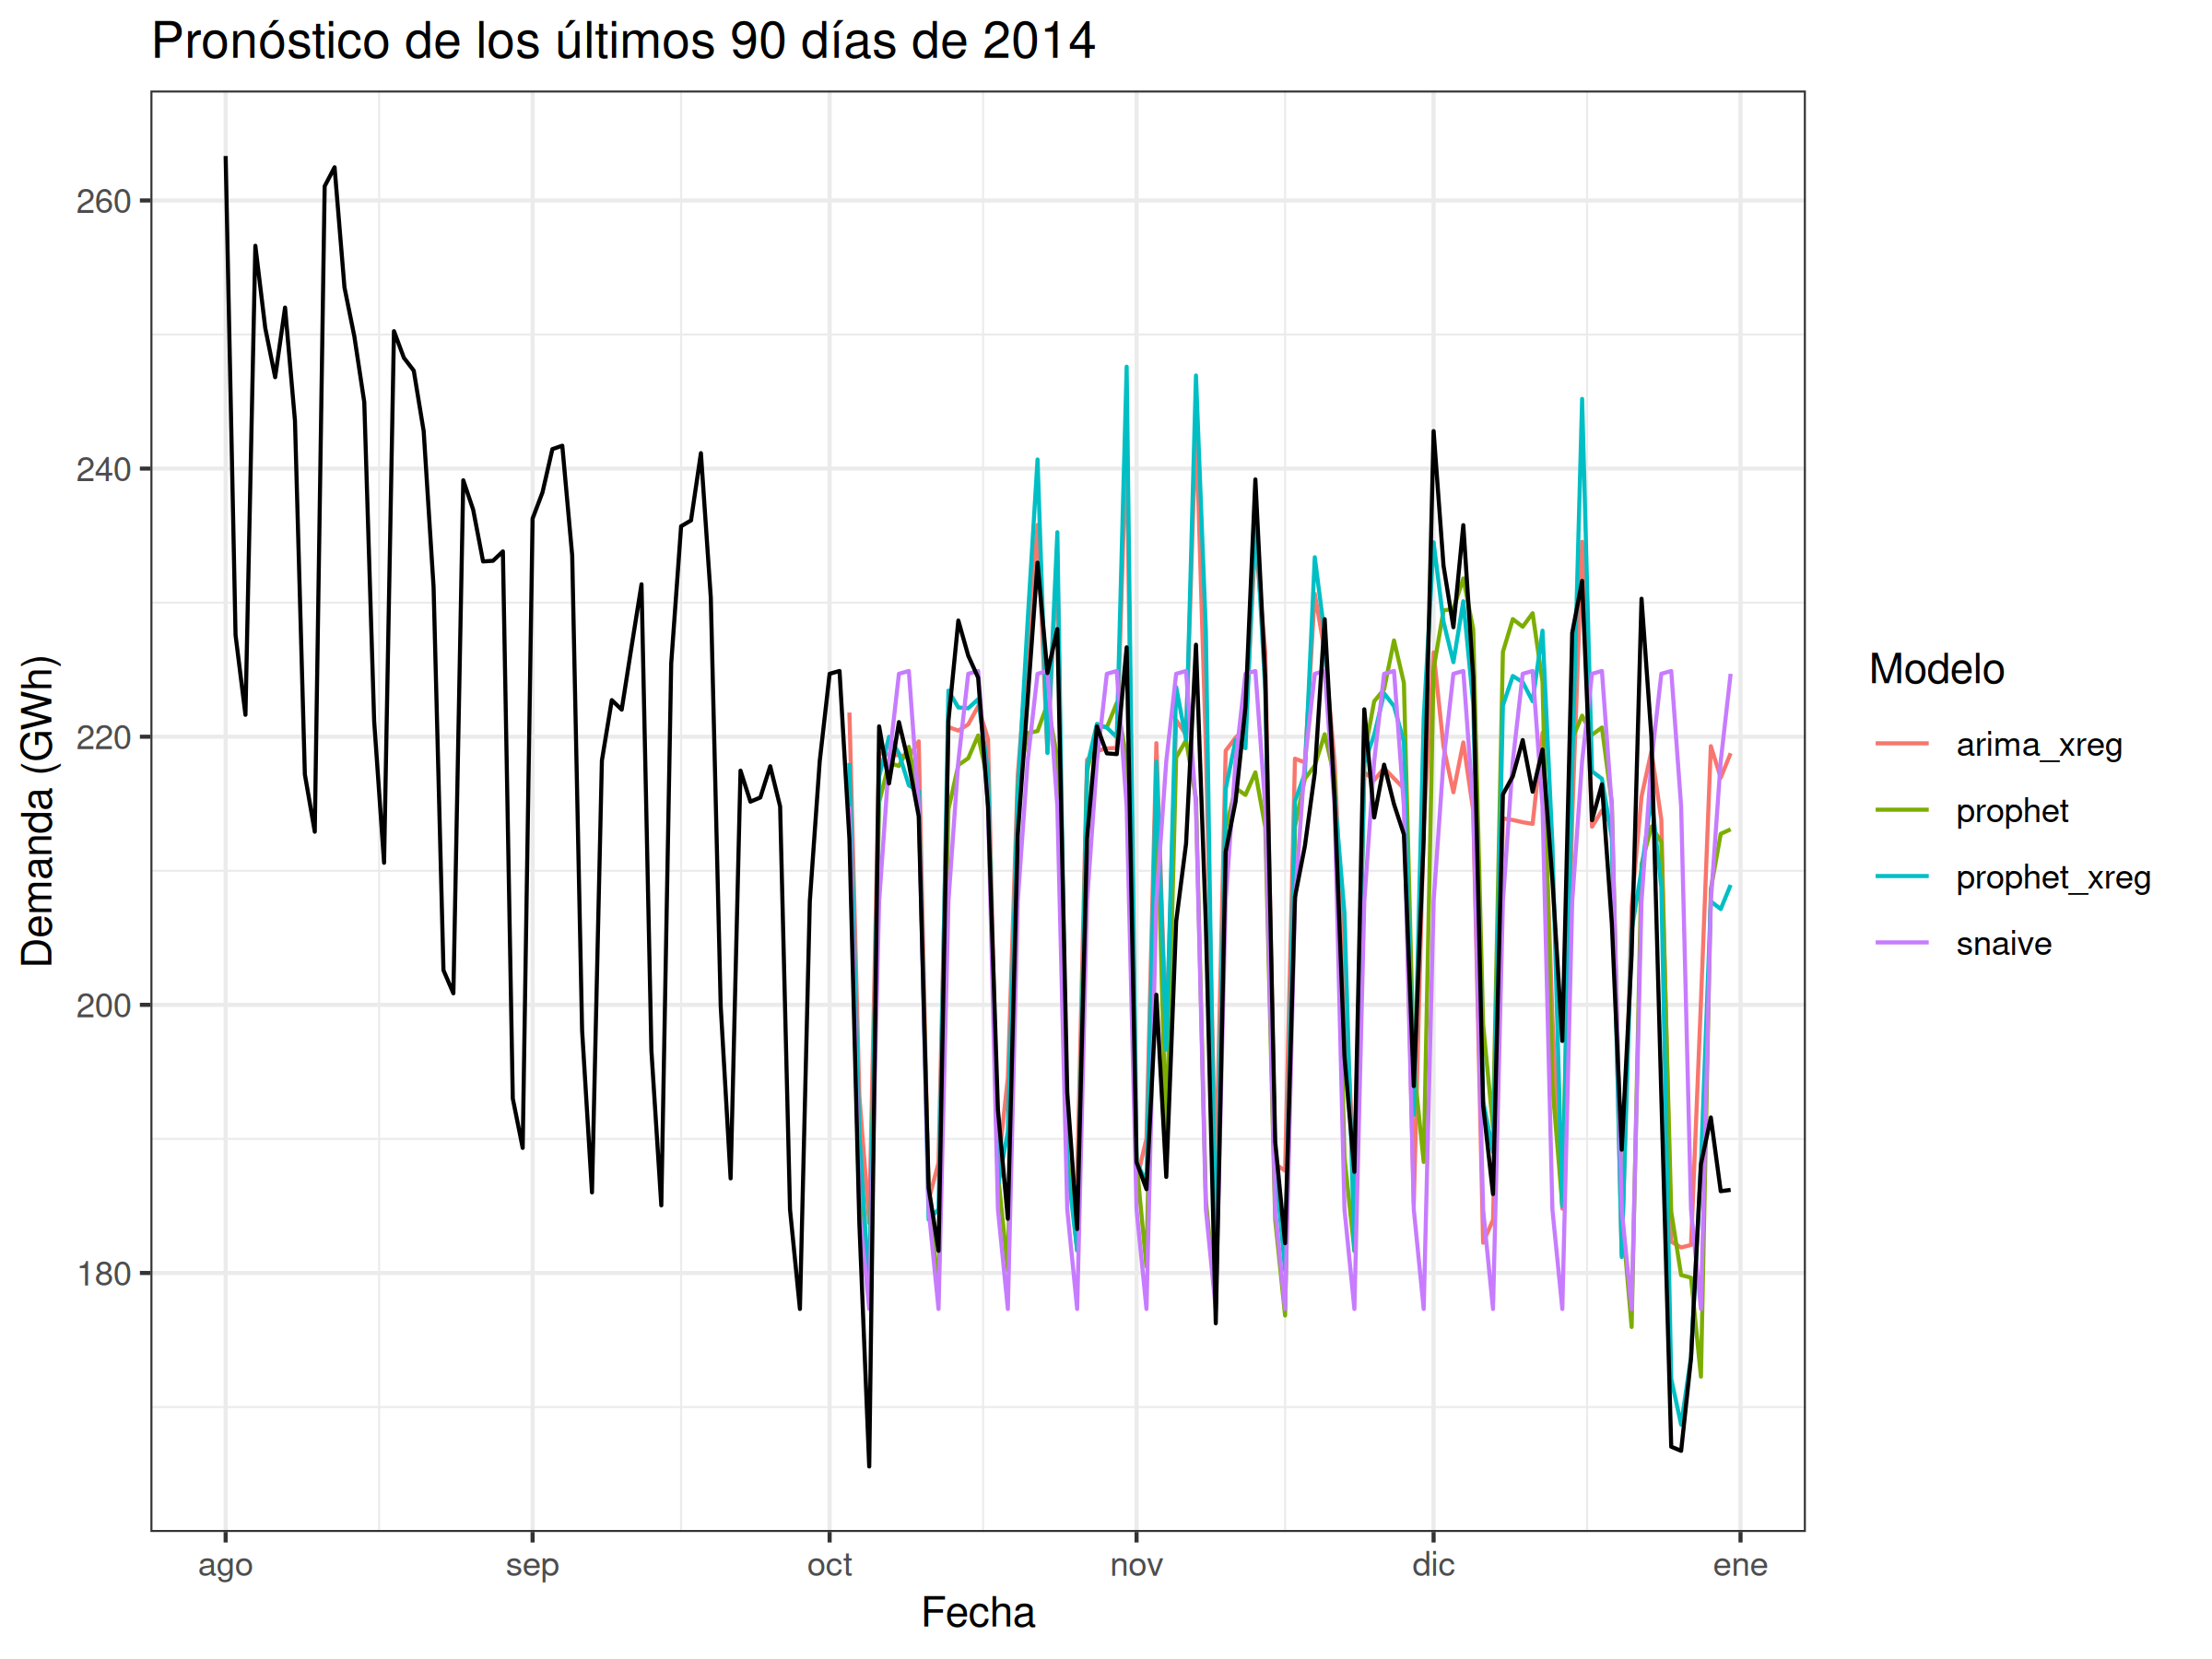

In [14]:
fc <- fit |> forecast(new_data = test)

fc |>
  autoplot(elec |> filter(Fecha >= ymd("2014-08-01")), level = NULL) +
  labs(x = "Fecha", y = "Demanda (GWh)", colour = "Modelo",
       title = "Pronóstico de los últimos 90 días de 2014")

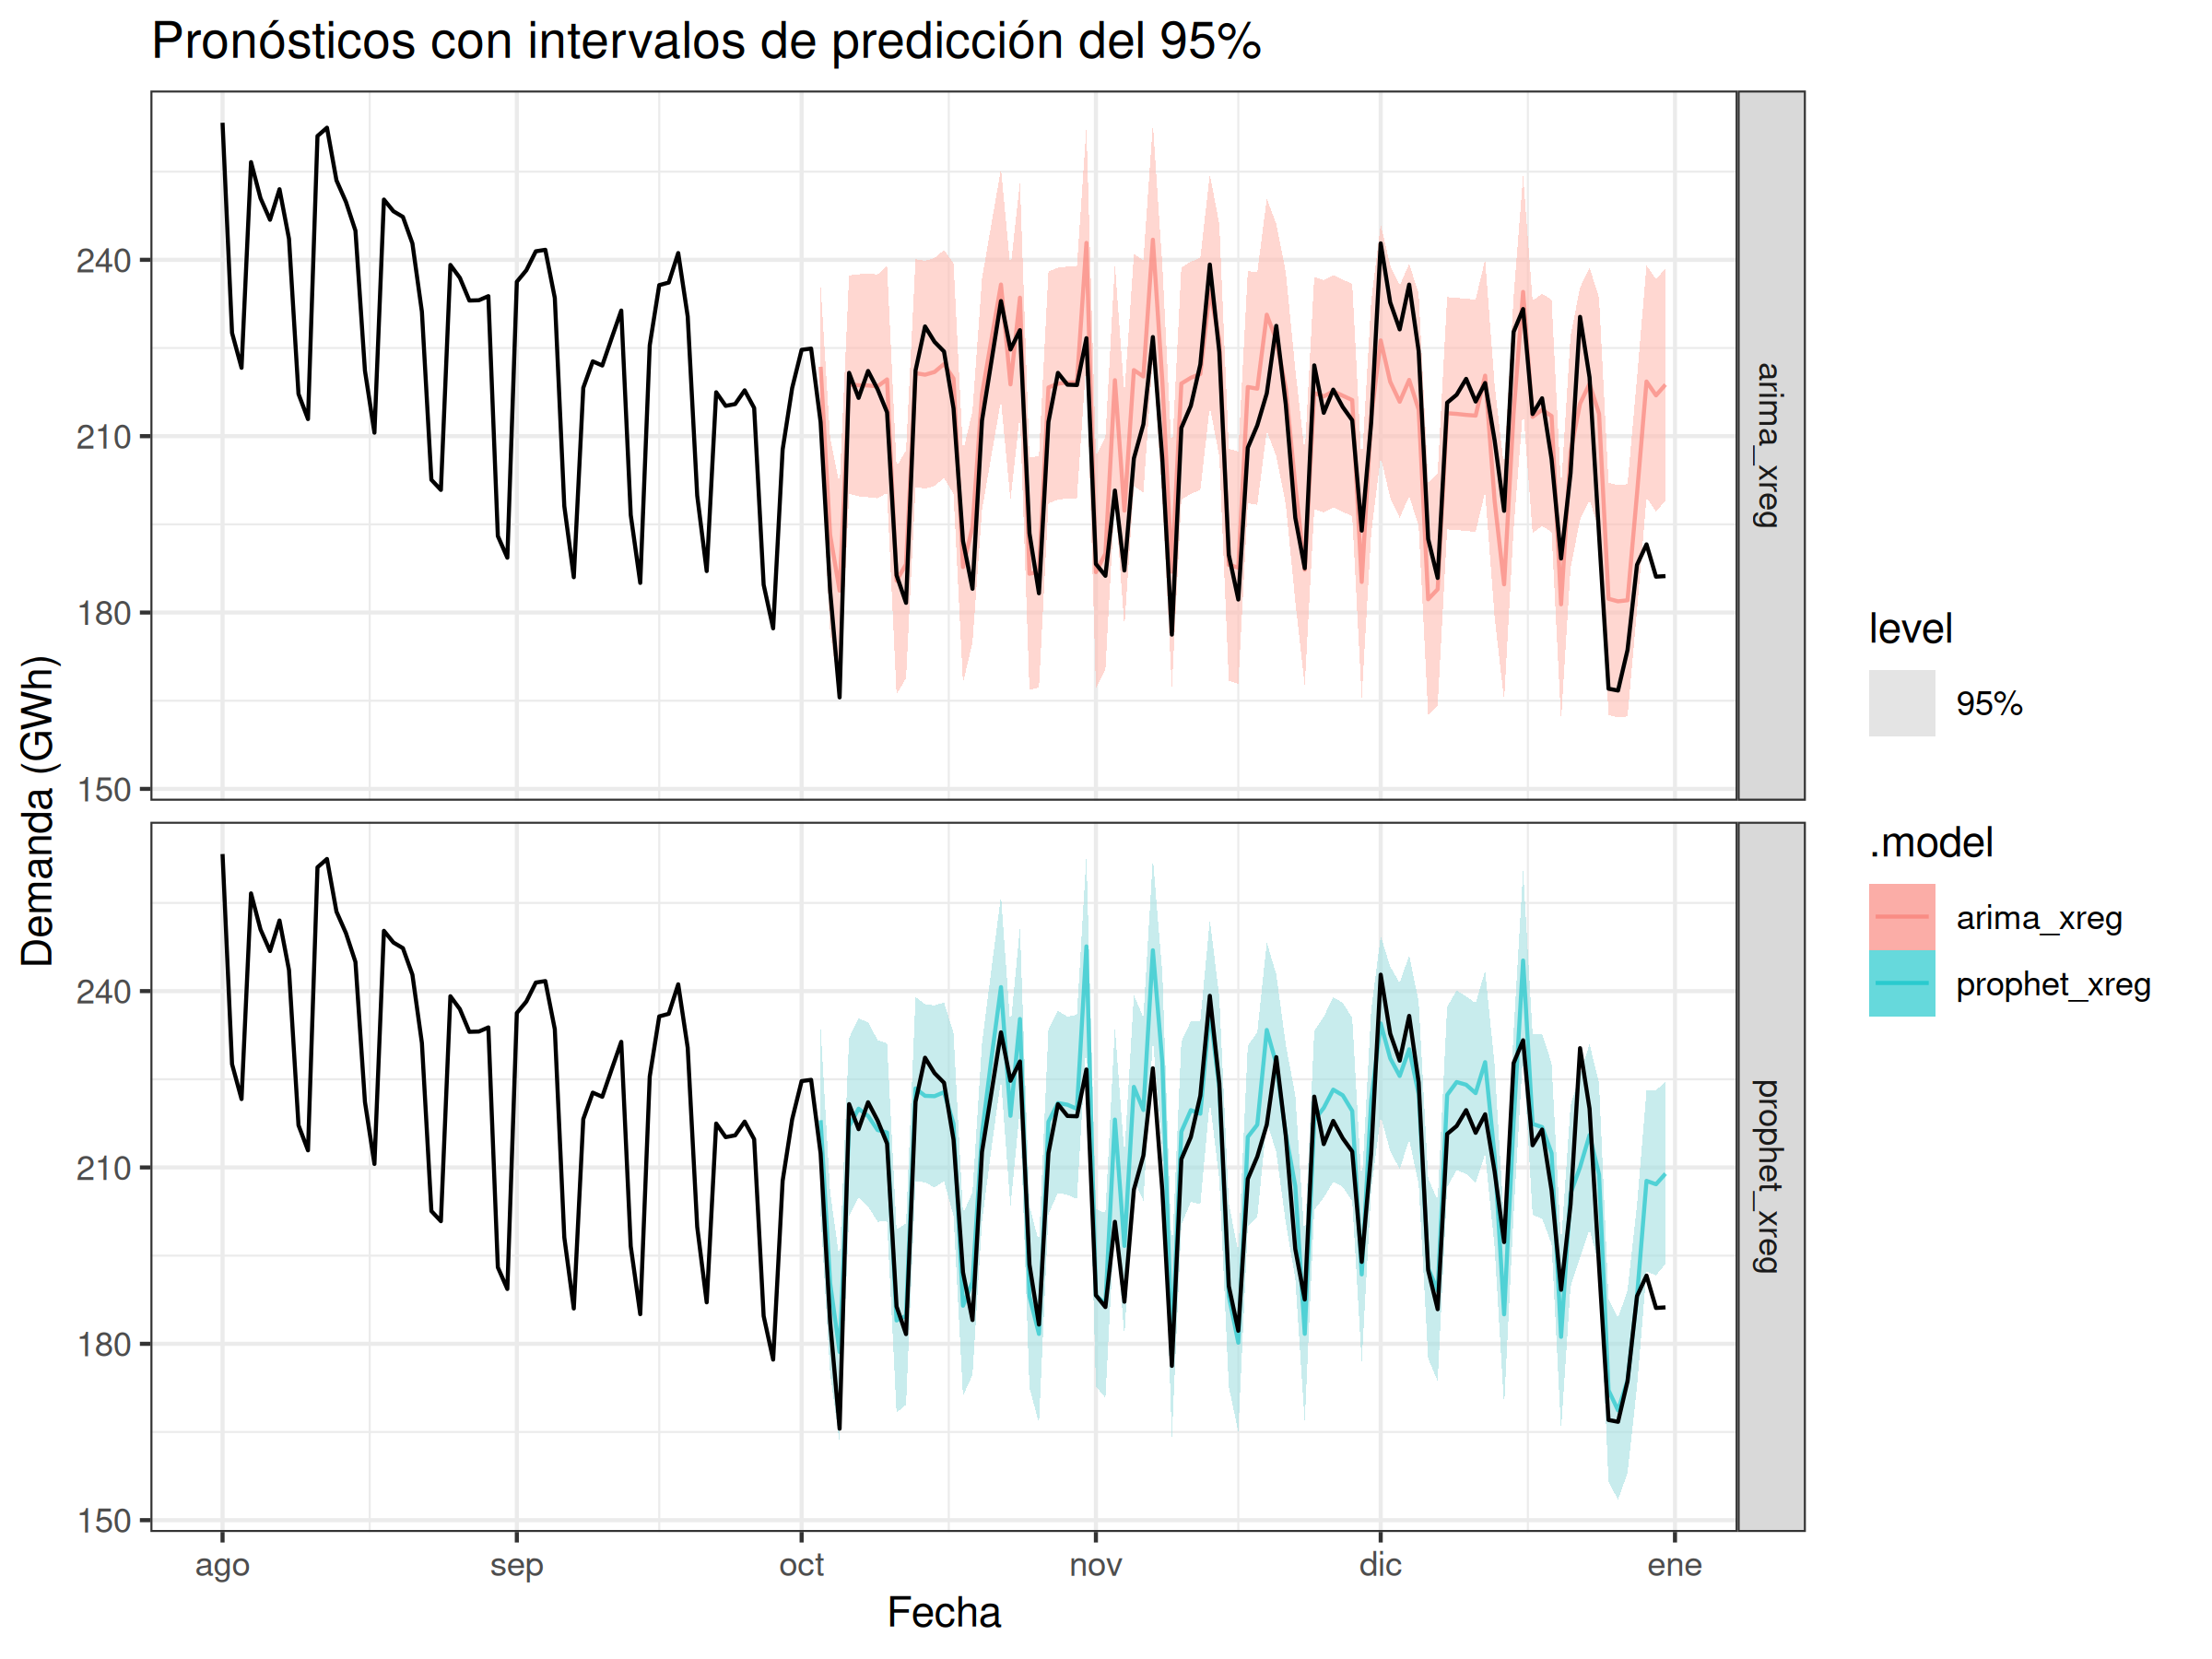

In [15]:
fc |>
  filter(.model %in% c("prophet_xreg", "arima_xreg")) |>
  autoplot(elec |> filter(Fecha >= ymd("2014-08-01")), level = 95, alpha = 0.6) +
  facet_grid(.model ~ .) +
  labs(x = "Fecha", y = "Demanda (GWh)",
       title = "Pronósticos con intervalos de predicción del 95%")

In [16]:
accuracy(fc, elec) |>
  select(.model, RMSE, MAE, MAPE) |>
  arrange(RMSE)

.model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
prophet_xreg,8.485285,6.337733,3.063408
arima_xreg,10.061738,7.492689,3.708077
prophet,10.343260,8.017806,3.897481
snaive,15.195953,10.776437,5.343388


**Interpretación**

- Los tres modelos pronostican mejor que el ingenuo estacional. El modelo Prophet con regresoras tiene el menor error, con un RMSE de 8.5 GWh y un MAPE de 3.1%.
- La regresión con errores ARIMA queda en segundo lugar a pesar de tener mejores residuos. La autocorrelación de los errores ayuda a pronosticar los primeros días, pero su efecto desaparece rápido, y para un horizonte de 90 días lo que más importa es describir bien la estacionalidad anual y el efecto de la temperatura.
- El gráfico muestra que los dos modelos con regresoras siguen bien el patrón semanal y los picos por calor. Los dos sobreestiman la demanda de los últimos días de diciembre, cuando la actividad cae por las vacaciones de fin de año.

## Validación cruzada de series de tiempo

- Una sola partición de entrenamiento y prueba depende de qué días quedaron en la prueba. La validación cruzada repite la evaluación en varias fechas de corte dentro del conjunto de entrenamiento (sección 5.10 de FPP3).
- La función `stretch_tsibble()` crea conjuntos de entrenamiento cada vez más largos. Usamos un entrenamiento inicial de 730 días, para que los modelos vean dos ciclos anuales completos, y agregamos 90 días en cada corte. Conservamos los tres cortes que tienen 90 días completos para evaluar dentro del conjunto de entrenamiento, igual que en el notebook de Python.
- Los modelos con regresoras necesitan los valores futuros de las regresoras en cada corte. Los construimos con `new_data()` y los unimos con los datos observados.

In [17]:
train_cv <- train |>
  stretch_tsibble(.init = 730, .step = 90) |>
  filter(.id <= 3)

train_cv |>
  as_tibble() |>
  group_by(.id) |>
  summarise(`Fecha de corte` = max(Fecha), Dias = n())

.id,Fecha de corte,Dias
<int>,<date>,<int>
1,2013-12-30,730
2,2014-03-30,820
3,2014-06-28,910


In [18]:
# Valores de las regresoras en los 90 días siguientes a cada corte
futuro_cv <- new_data(train_cv, h) |>
  left_join(as_tibble(train), by = "Fecha")

fit_cv <- train_cv |>
  model(
    snaive       = SNAIVE(Demand ~ lag("week")),
    prophet      = prophet(Demand ~ season("week") + season("year") + holiday(festivos)),
    prophet_xreg = prophet(Demand ~ Temperature + Temperature2 + Working_Day +
                             season("week") + season("year")),
    arima_xreg   = ARIMA(Demand ~ Temperature + I(Temperature^2) + Working_Day +
                           fourier(period = "year", K = 4) + pdq(d = 0))
  )

fc_cv <- fit_cv |> forecast(new_data = futuro_cv)

accuracy(fc_cv, train) |>
  select(.model, RMSE, MAE, MAPE) |>
  arrange(RMSE)

.model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
prophet_xreg,10.78101,8.827461,3.895573
arima_xreg,12.44881,9.524833,4.293346
prophet,21.09375,14.016154,5.937196
snaive,34.28345,23.114332,9.737747


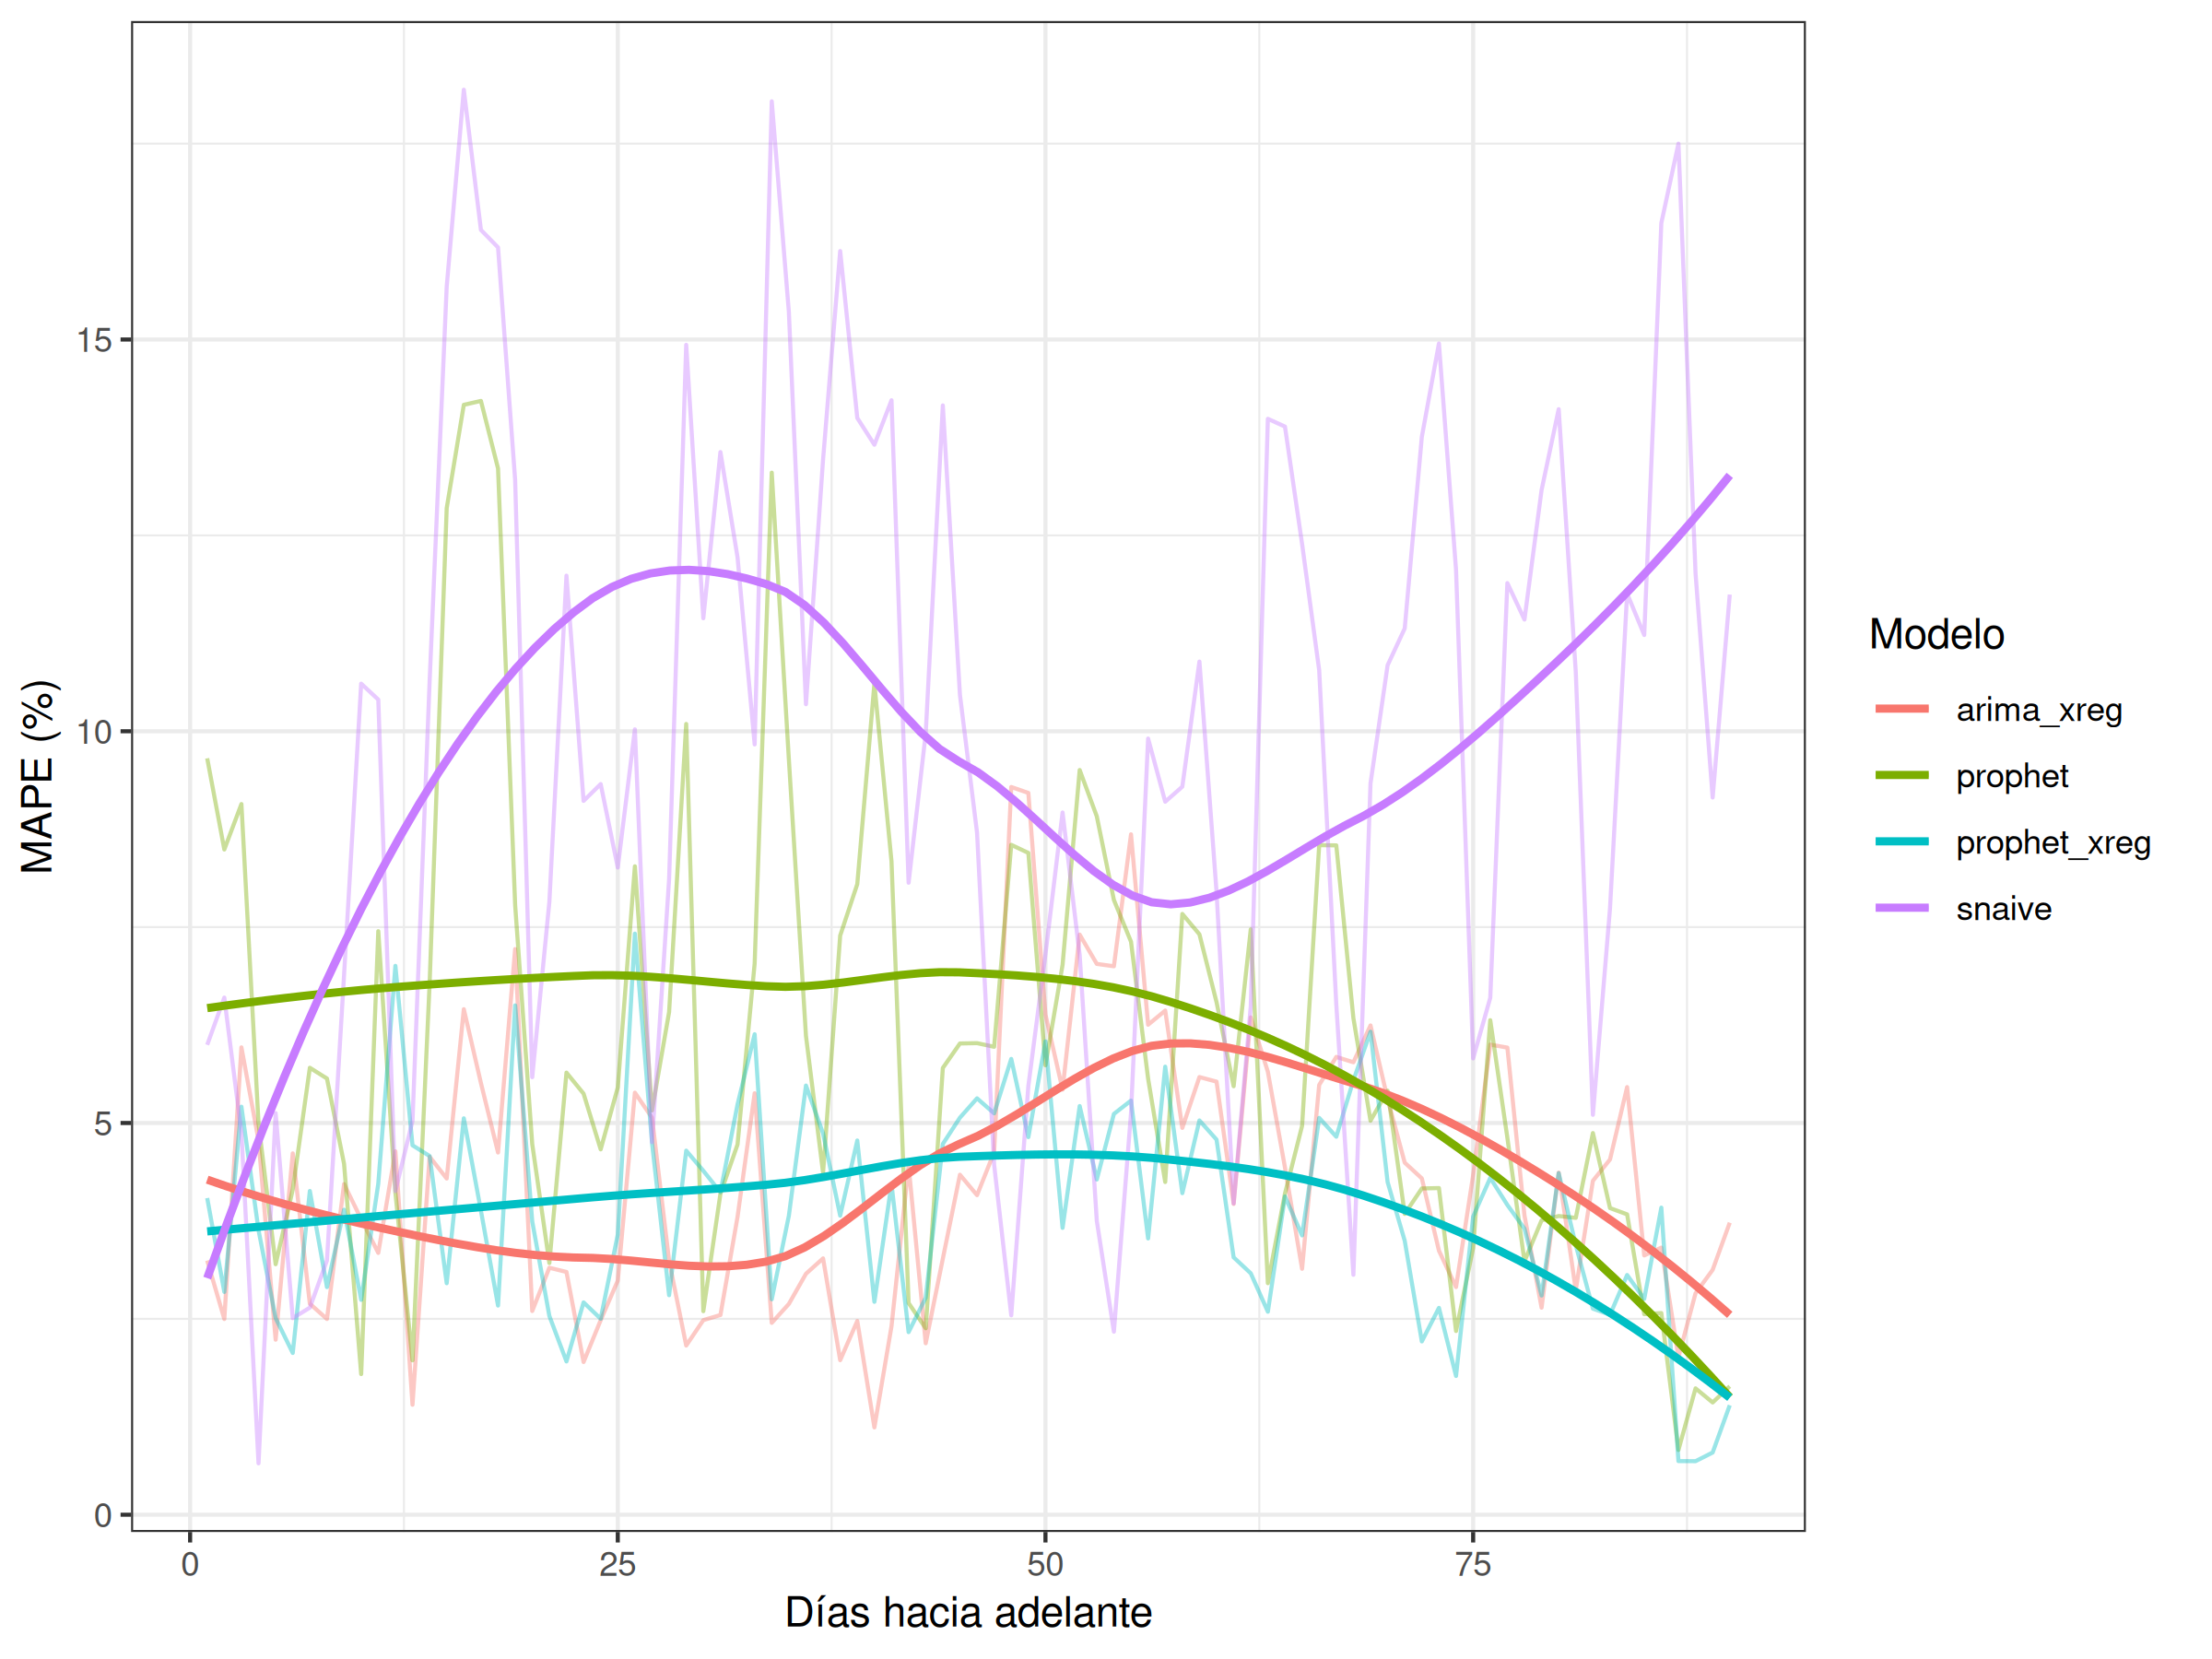

In [19]:
# Error según el número de días hacia adelante
fc_cv |>
  group_by(.id, .model) |>
  mutate(h = row_number()) |>
  ungroup() |>
  as_fable(response = "Demand", distribution = Demand) |>
  accuracy(train, by = c("h", ".model")) |>
  ggplot(aes(x = h, y = MAPE, colour = .model)) +
  geom_line(alpha = 0.4) +
  geom_smooth(se = FALSE, method = "loess", formula = y ~ x) +
  labs(x = "Días hacia adelante", y = "MAPE (%)", colour = "Modelo")

**Interpretación**

- La validación cruzada confirma el orden de los modelos del conjunto de prueba. Prophet con regresoras tiene el menor error, seguido de la regresión con errores ARIMA. Los errores son mayores que en el conjunto de prueba porque los cortes incluyen el verano de 2014, con olas de calor difíciles de pronosticar.
- El ingenuo estacional y Prophet sin regresoras tienen errores mucho mayores en la validación cruzada, porque los periodos que pronostican incluyen cambios de estación que la temperatura sí ayuda a explicar.
- En el gráfico cada línea delgada es el MAPE promedio de los tres cortes para cada número de días hacia adelante, y la línea gruesa es una suavización. El error de los modelos con regresoras no crece con el horizonte porque usan la temperatura observada en cada día. Con solo tres cortes las curvas son muy variables, por lo que no conviene interpretar sus detalles.

## Ajuste de hiperparámetros

- Usamos la validación cruzada para elegir `changepoint_prior_scale`, que controla la flexibilidad de la tendencia y se fija dentro de `growth()`, y `prior_scale` de `season()`, que controla la flexibilidad de la estacionalidad.
- Creamos una lista con un modelo por cada combinación de la grilla y la pasamos a `model()` con el operador `!!!`. Se elige la combinación con menor RMSE en la validación cruzada.

In [20]:
grilla <- expand_grid(
  changepoint_prior_scale = c(0.01, 0.05, 0.5),
  seasonality_prior_scale = c(0.1, 10)
)

modelos_grilla <- grilla |>
  pmap(\(changepoint_prior_scale, seasonality_prior_scale)
    prophet(Demand ~ Temperature + Temperature2 + Working_Day +
              growth(changepoint_prior_scale = changepoint_prior_scale) +
              season("week", prior_scale = seasonality_prior_scale) +
              season("year", prior_scale = seasonality_prior_scale))) |>
  set_names(paste0("cps_", grilla$changepoint_prior_scale,
                   "_sps_", grilla$seasonality_prior_scale))

tabla_grilla <- train_cv |>
  model(!!!modelos_grilla) |>
  forecast(new_data = futuro_cv) |>
  accuracy(train) |>
  select(.model, RMSE, MAPE) |>
  arrange(RMSE)

tabla_grilla

.model,RMSE,MAPE
<chr>,<dbl>,<dbl>
cps_0.01_sps_0.1,9.841304,3.533276
cps_0.01_sps_10,9.893946,3.537668
cps_0.05_sps_0.1,10.758768,3.879577
cps_0.05_sps_10,10.779172,3.893284
cps_0.5_sps_0.1,11.291259,4.008703
cps_0.5_sps_10,11.378889,4.046145


In [21]:
# Reestimar el mejor modelo con todo el conjunto de entrenamiento
mejor <- tabla_grilla$.model[1]
mejor

fit_ajustado <- train |>
  model(prophet_ajustado = modelos_grilla[[mejor]])

fc_ajustado <- fit_ajustado |> forecast(new_data = test)

[1] "cps_0.01_sps_0.1"

## Comparación de modelos en el conjunto de prueba

In [22]:
fc_todos <- bind_rows(fc, fc_ajustado)

accuracy(fc_todos, elec) |>
  select(.model, RMSE, MAE, MAPE) |>
  arrange(RMSE)

.model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
prophet_ajustado,7.960663,6.144541,2.956635
prophet_xreg,8.485285,6.337733,3.063408
arima_xreg,10.061738,7.492689,3.708077
prophet,10.343260,8.017806,3.897481
snaive,15.195953,10.776437,5.343388


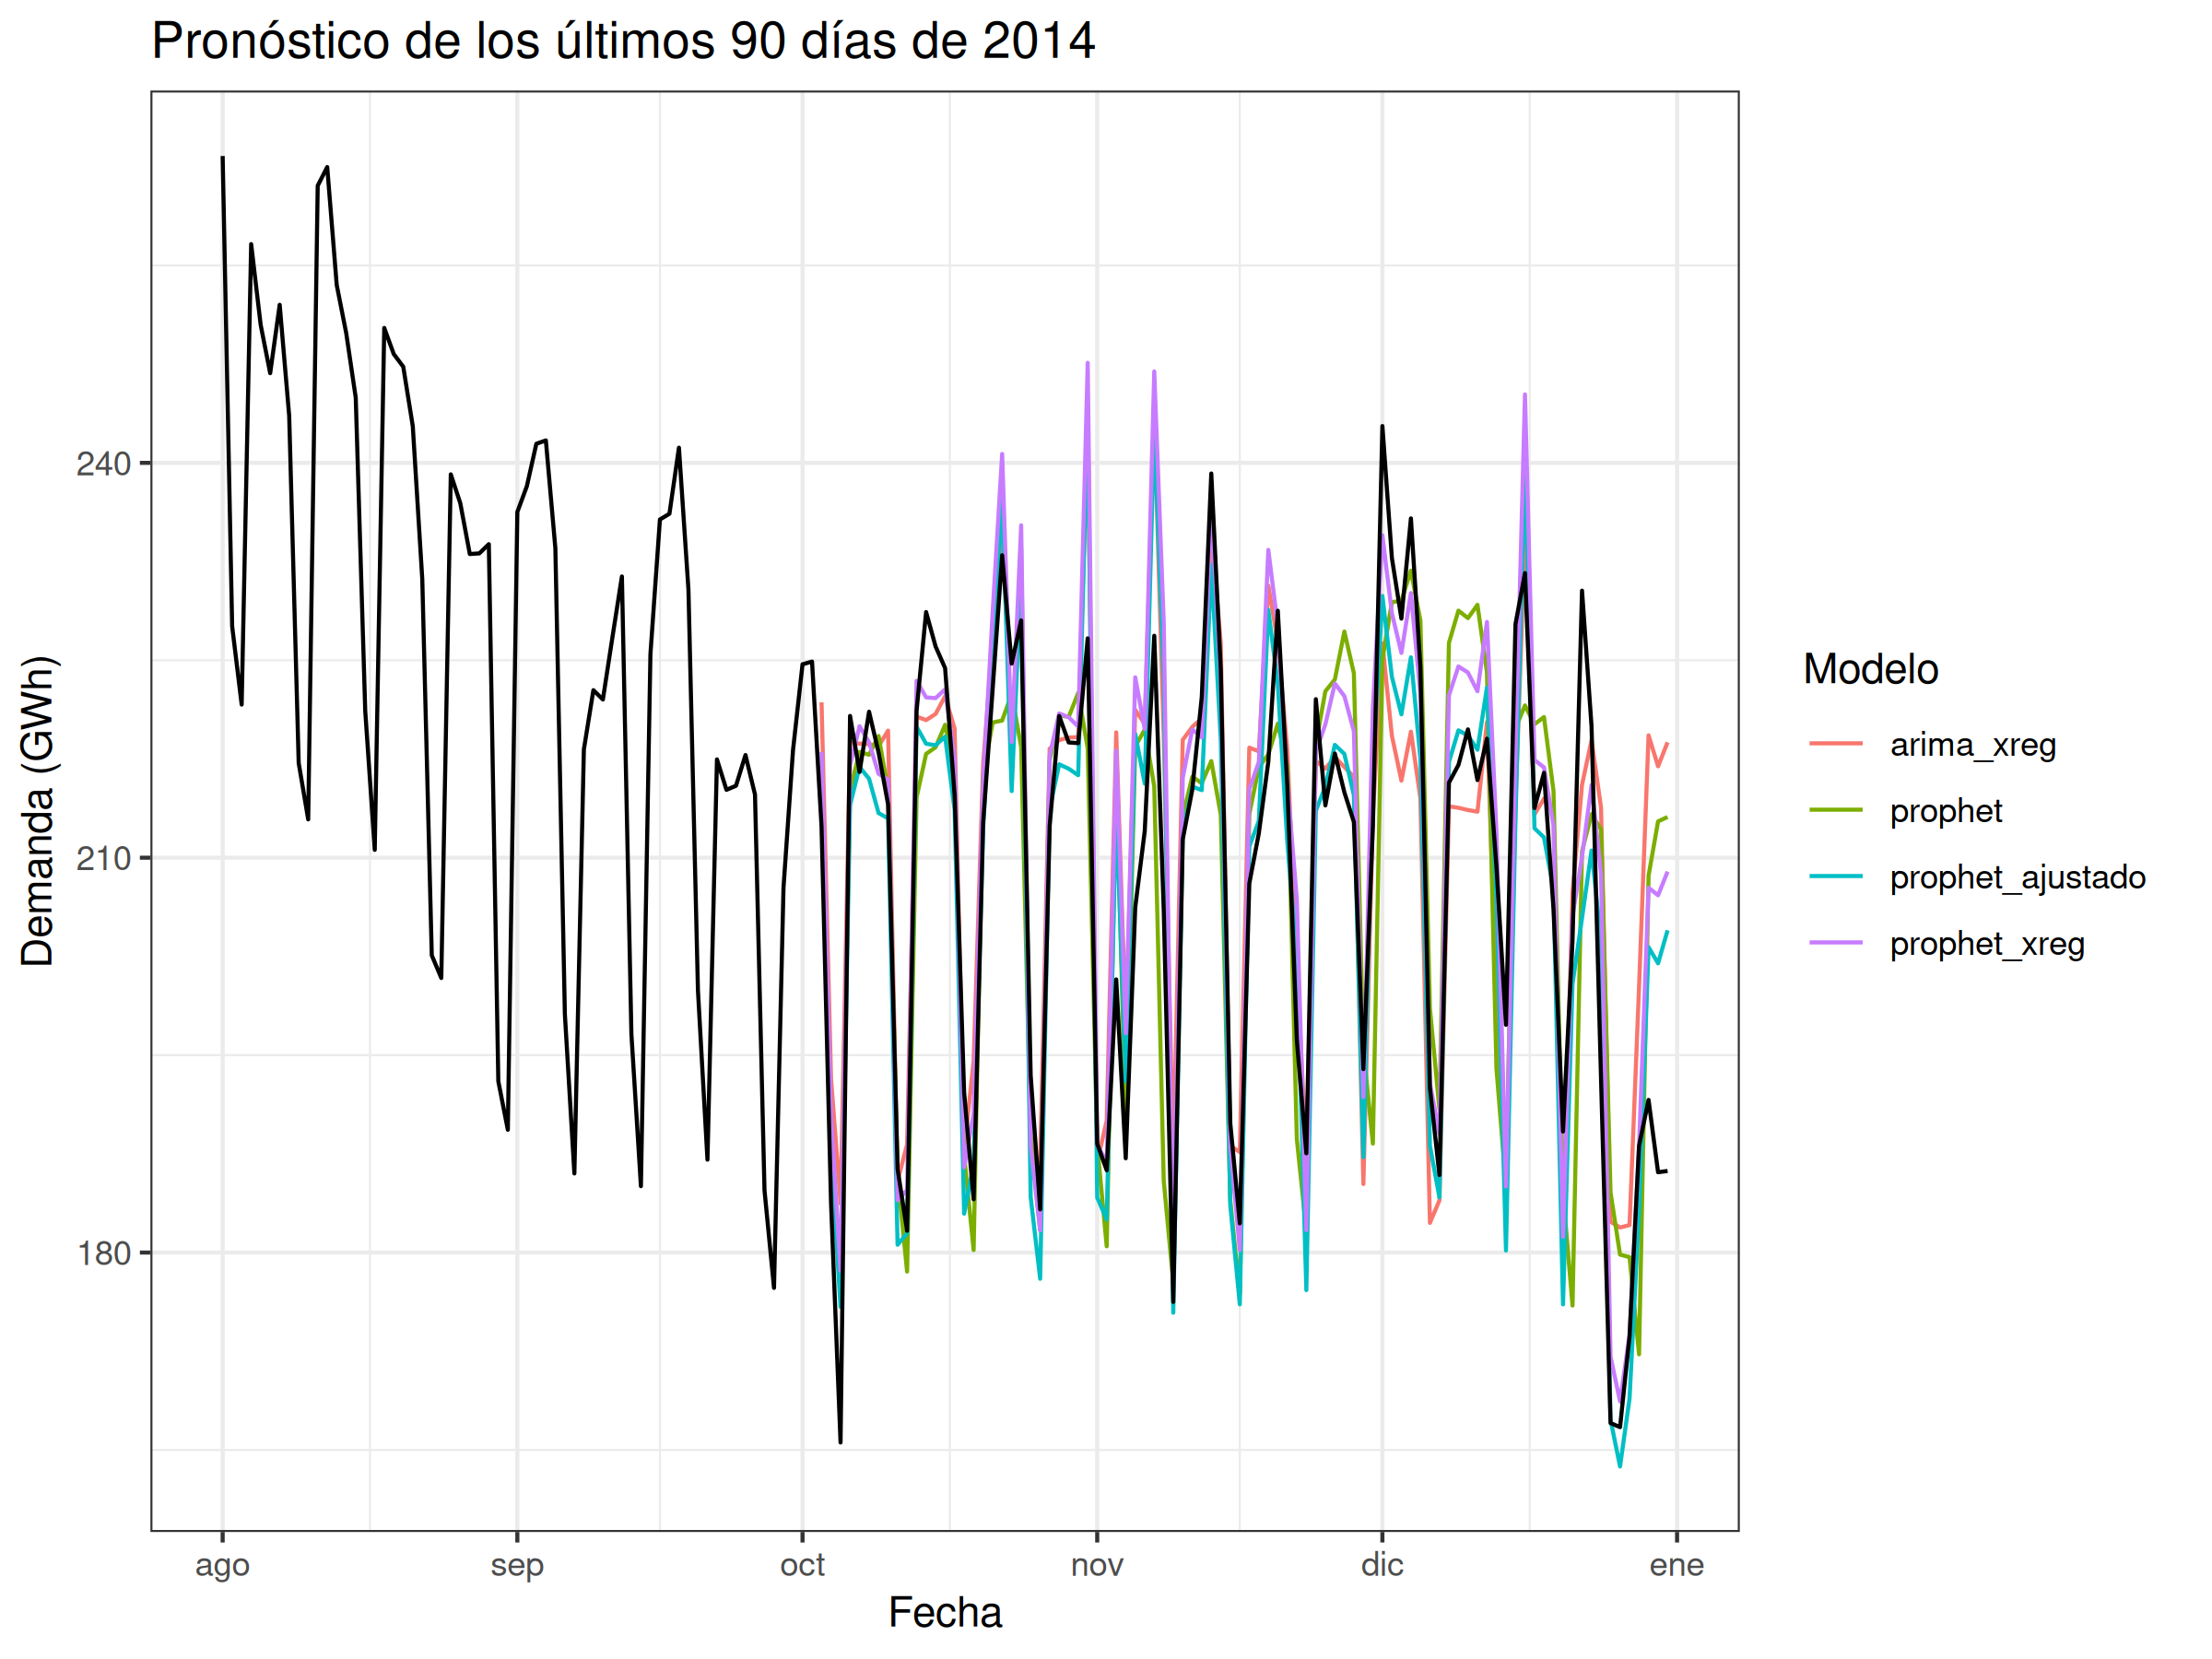

In [23]:
fc_todos |>
  filter(.model != "snaive") |>
  autoplot(elec |> filter(Fecha >= ymd("2014-08-01")), level = NULL) +
  labs(x = "Fecha", y = "Demanda (GWh)", colour = "Modelo",
       title = "Pronóstico de los últimos 90 días de 2014")

## Conclusiones

- Todos los modelos pronostican mejor que el ingenuo estacional. El modelo Prophet con regresoras y con los hiperparámetros ajustados reduce el RMSE de 15.2 a cerca de 8 GWh y el MAPE de 5.3% a cerca de 3%.
- La mayor mejora viene de agregar la temperatura y el día laboral. Esto coincide con el gráfico de dispersión, que muestra que la demanda depende de la temperatura de forma no lineal y que es mayor en los días laborales.
- El ajuste de hiperparámetros eligió un `changepoint_prior_scale` de 0.01, es decir, una tendencia más rígida. Con solo tres años de datos, una tendencia flexible sigue cambios que no se mantienen en el futuro. El valor de `prior_scale` de la estacionalidad casi no cambia el error.
- La regresión con errores ARIMA del enfoque de FPP3 es un modelo competitivo y más fácil de interpretar, porque sus coeficientes miden directamente el efecto de la temperatura y del día laboral. En este ejemplo Prophet pronostica mejor a 90 días, aunque sus residuos están autocorrelacionados.
- Los modelos con regresoras usaron la temperatura observada en el periodo de prueba. En un pronóstico real se usaría el pronóstico del clima, por lo que el error sería mayor que el reportado aquí.
- Los resultados coinciden con los del notebook de Python (RMSE de 7.96 GWh para el modelo ajustado) y se pueden comparar con los del notebook de LSTM, que usa los mismos datos y el mismo periodo de prueba.